# Task B05: HMDA 2024 Comprehensive 99-Column Profiling, Extended EDA & Rule Calibration (v5.1 / Reconciled Post-Audit)

**Project:** Decomposing Racial Gaps in Mortgage Denial Rates: A Large-Scale Analysis of the 2024 U.S. HMDA Market  
**Course:** Big Data Analysis (Final Project) — Group 3  
**Milestone:** Task B05 (v5.1 Reconciled) — Profiling 12.26M Raw Applications, Dictionary-Backed 23-Column Numeric Audit, Non-Circular X09 Audit, Per-Field T12 Calibration & Corrected Dual S5 Evaluation  
**Companion Artifacts:** `data_cleaning_plan.md`, `data_cleaning_rules.md` (v2.3 reconciled), `decisions.md` (Locked D-A through D-I)

## Section 1: Configuration, Shared Predicates & Environment Setup

- **Input:** Raw Parquet dataset `B04_raw_with_buckets.parquet`, official `HMDA_Public_LAR_Data_Dictionary.xlsx` (resolved from `input/` or `origin/`), and environment variables.
- **Process:**
  - Resolve directory paths via `pathlib.Path` with fallback check (`input/` then `origin/`) for `HMDA_Public_LAR_Data_Dictionary.xlsx` per Convention 1 & 2.
  - Initialize **DuckDB** (in-process SQL OLAP engine executing vectorized queries directly on Parquet files) with 8 GB RAM limit, 4 threads, and spill directory `output/duckdb_temp`.
  - Define canonical uppercase sentinel tuples (`SENTINELS_NUM`, `SENTINELS_CODED`) and the single reusable NULL-safe SQL predicate `S0_SQL_PRED` to eliminate copy-paste errors across sections.
- **Output:** Configured runtime environment and verified paths.

In [ ]:
# Step 1: Standard library and analytical package imports
import sys, json, duckdb
import pandas as pd
from pathlib import Path

# Step 2: Resolve workspace paths and assert presence of raw parquet and data dictionary
# [CHANGE] Step 2: use local input/ copy if present, else read B04 output directly (no 450 MB copy)
SCRIPT_DIR = Path.cwd()
ROOT = next((p for p in [SCRIPT_DIR, *SCRIPT_DIR.parents] if (p / "origin").exists()), SCRIPT_DIR)
INPUT_CANDIDATES = [SCRIPT_DIR / "input" / "B04_raw_with_buckets.parquet",
                    ROOT / "B04 - 30 Oct" / "output" / "B04_raw_with_buckets.parquet"]
INPUT_PARQUET = next((p for p in INPUT_CANDIDATES if p.exists()), None)
assert INPUT_PARQUET is not None, f"Run B04 first. Looked in: {[str(p) for p in INPUT_CANDIDATES]}"

DICT_CANDIDATES = [
    SCRIPT_DIR / "input" / "HMDA_Public_LAR_Data_Dictionary.xlsx",
    SCRIPT_DIR.parent / "origin" / "HMDA_Public_LAR_Data_Dictionary.xlsx",
    Path("HMDA_Public_LAR_Data_Dictionary.xlsx")
]
DATA_DICT_PATH = next((p for p in DICT_CANDIDATES if p.exists()), None)
assert DATA_DICT_PATH is not None, f"Data dictionary not found in {[str(p) for p in DICT_CANDIDATES]}"

OUTPUT_DIR, TEMP_SPILL = SCRIPT_DIR / "output", SCRIPT_DIR / "output" / "duckdb_temp"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True); TEMP_SPILL.mkdir(parents=True, exist_ok=True)

# Step 3: Initialize DuckDB in-process OLAP engine with resource controls
duck_conn = duckdb.connect()
duck_conn.execute("SET memory_limit = '8GB'; SET threads = 4;")
duck_conn.execute(f"SET temp_directory = '{TEMP_SPILL.as_posix()}';")

# Step 4: Canonical SQL predicates (positive set membership per D-A) and sentinel sets
SENTINELS_NUM = "('', 'NA', 'EXEMPT')"
SENTINELS_CODED = "('', 'NA', 'EXEMPT', '1111', '8888', '9999')"
S0_SQL_PRED = (
    "TRIM(action_taken) IN ('1', '2', '3') "
    "AND TRIM(business_or_commercial_purpose) IN ('2', '1111') "
    "AND TRIM(reverse_mortgage) IN ('2', '1111')"
)
print("[OK] Environment configured. Input parquet and Data Dictionary verified.")

[OK] Environment configured. Input parquet and Data Dictionary verified.


## Section 1.1: Reusable Artifact Export & Logging Helper

- **Input:** A pandas DataFrame `df` and target `filename` string.
- **Process:**
  - Save `df` to `output/<filename>` as UTF-8 CSV without index.
  - Measure physical file size via `Path.stat().st_size` and print the full path, size in KB and bytes, and `(rows, cols)` shape per Convention 3.8.
- **Output:** Saved CSV artifact and standardized verification log.

In [47]:
# Step 1: Define reusable helper function for standardized artifact logging
def save_and_log(df: pd.DataFrame, filename: str) -> Path:
    target_path = OUTPUT_DIR / filename
    try:
        df.to_csv(target_path, index=False, encoding="utf-8")
    except PermissionError:
        print(f"[Warning] Could not overwrite {filename} (file open in another program). Keeping existing file.")
    size_bytes = target_path.stat().st_size
    print(f"Saved: {target_path} | Size: {size_bytes/1024.0:.2f} KB ({size_bytes:,} bytes) | Shape: {df.shape}")
    return target_path


## Section 2.1: Step B-2.1 — Full 99-Column Whitespace & Sentinel Profiling (Rules T01, T02, T09)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Audit all 99 raw HMDA columns for leading/trailing whitespace (`"{c}" != TRIM("{c}")`) to test Rule T01.
  - Count Blank `""`, case-insensitive `'NA'`, `'EXEMPT'`, `'1111'`, `'8888'`, and `'9999'` after `TRIM("{c}")`.
  - Compute both `missing_sentinel_count` (`na + exempt`) and `missing_total_count` (`blank + na + exempt`) along with their respective dataset percentages.
- **Output:** Master 99-column profile exported to `output/B05_sentinels_99_columns.csv` and interactive display of all 48 columns with `missing_total_count > 0` sorted descending by missing percentage.

In [48]:
# Step 1: Extract raw HMDA column names, total row count, and Dictionary Number-type fields
schema_df = duck_conn.execute(f"DESCRIBE SELECT * FROM read_parquet('{INPUT_PARQUET.as_posix()}')").df()
raw_hmda_cols = [c for c in schema_df['column_name'] if c not in ('row_id', 'bucket')]
total_raw_rows = duck_conn.execute(f"SELECT COUNT(*)::BIGINT FROM read_parquet('{INPUT_PARQUET.as_posix()}')").fetchone()[0]
assert len(raw_hmda_cols) == 99 and total_raw_rows == 12259199, 'Row/Col count mismatch'
dict_df = pd.read_excel(DATA_DICT_PATH, sheet_name='Data_Dictionary')
dict_is_number = set(dict_df[dict_df['Data Type (chuẩn hóa)'].astype(str).str.startswith('Number', na=False)]['Field Name'])

# Step 2: Build high-performance SQL aggregating whitespace and sentinel tallies
agg_clauses = []
for c in raw_hmda_cols:
    c_esc = f'"{c}"'
    agg_clauses.extend([
        f'COUNT(*) FILTER (WHERE {c_esc} != TRIM({c_esc}))::BIGINT AS "{c}__padded"',
        f'COUNT(*) FILTER (WHERE TRIM({c_esc}) = \'\')::BIGINT AS "{c}__blank"',
        f'COUNT(*) FILTER (WHERE UPPER(TRIM({c_esc})) = \'NA\')::BIGINT AS "{c}__na"',
        f'COUNT(*) FILTER (WHERE UPPER(TRIM({c_esc})) = \'EXEMPT\')::BIGINT AS "{c}__exempt"',
        f'COUNT(*) FILTER (WHERE TRIM({c_esc}) = \'1111\')::BIGINT AS "{c}__1111"', f'COUNT(*) FILTER (WHERE TRIM({c_esc}) = \'8888\')::BIGINT AS "{c}__8888"', f'COUNT(*) FILTER (WHERE TRIM({c_esc}) = \'9999\')::BIGINT AS "{c}__9999"'
    ])
raw_profile_res = duck_conn.execute(f"SELECT {', '.join(agg_clauses)} FROM read_parquet('{INPUT_PARQUET.as_posix()}')").fetchone()

# Step 3: Reshape profiling results into 99-row master audit DataFrame using Dictionary-backed types
rows = []
for i, c in enumerate(raw_hmda_cols):
    pad, blk, na, ex, c1111, c8888, c9999 = raw_profile_res[i*7: i*7 + 7]
    sem = 'Numeric/Financial' if c in dict_is_number else 'Categorical/Code'
    rows.append({
        'column_name': c, 'semantic_type': sem, 'padded_count': pad, 'blank_count': blk, 'na_count': na, 'exempt_count': ex,
        'code_1111_count': c1111, 'code_8888_count': c8888, 'code_9999_count': c9999,
        'missing_sentinel_count': na + ex, 'missing_sentinel_pct': round((na + ex) * 100.0 / total_raw_rows, 4),
        'missing_total_count': blk + na + ex, 'missing_total_pct': round((blk + na + ex) * 100.0 / total_raw_rows, 4)
    })
sentinels_99_df = pd.DataFrame(rows)
save_and_log(sentinels_99_df, 'B05_sentinels_99_columns.csv')

# Step 4: Display all columns with total missing > 0, sorted descending by missing percentage
missing_99_df = sentinels_99_df[sentinels_99_df['missing_total_count'] > 0].sort_values(by='missing_total_count', ascending=False)
print(f'[Profile Insight] {len(missing_99_df)} of 99 columns contain missing sentinels or blanks.')
display(missing_99_df)


Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_sentinels_99_columns.csv | Size: 7.53 KB (7,706 bytes) | Shape: (99, 13)
[Profile Insight] 48 of 99 columns contain missing sentinels or blanks.


,column_name,semantic_type,padded_count,blank_count,na_count,exempt_count,code_1111_count,code_8888_count,code_9999_count,missing_sentinel_count,missing_sentinel_pct,missing_total_count,missing_total_pct
58,co_applicant_ethnicity_5,Categorical/Code,0,12259159,0,0,0,0,0,0,0.0000,12259159,99.9997
57,co_applicant_ethnicity_4,Categorical/Code,0,12259061,0,0,0,0,0,0,0.0000,12259061,99.9989
53,applicant_ethnicity_5,Categorical/Code,0,12259059,0,0,0,0,0,0,0.0000,12259059,99.9989
52,applicant_ethnicity_4,Categorical/Code,0,12258720,0,0,0,0,0,0,0.0000,12258720,99.9961
70,co_applicant_race_5,Categorical/Code,0,12258281,0,0,0,0,0,0,0.0000,12258281,99.9925
65,applicant_race_5,Categorical/Code,0,12256811,0,0,0,0,0,0,0.0000,12256811,99.9805
69,co_applicant_race_4,Categorical/Code,0,12256672,0,0,0,0,0,0,0.0000,12256672,99.9794
56,co_applicant_ethnicity_3,Categorical/Code,0,12254100,0,0,0,0,0,0,0.0000,12254100,99.9584
64,applicant_race_4,Categorical/Code,0,12252103,0,0,0,0,0,0,0.0000,12252103,99.9421
51,applicant_ethnicity_3,Categorical/Code,0,12243792,0,0,0,0,0,0,0.0000,12243792,99.8743


## Section 2.2: Step B-2.1 — Numeric Castability & Unparseable String Audit (Rule T03)

- **Input:** `B04_raw_with_buckets.parquet` and `sentinels_99_df` filtered to all `Numeric/Financial` columns.
- **Process:**
  - Test **Rule T03** across all numeric columns by attempting `try_cast(TRIM(col) AS DOUBLE)` on every non-sentinel value (`UPPER(TRIM(col)) NOT IN ('', 'NA', 'EXEMPT')`).
  - Verify the Rule T03 audit equation: `valid_numeric_count + missing_total_count + unparseable_count == total_raw_rows`, and assert `unparseable_count == 0` across all numeric columns.
- **Output:** Castability audit table exported to `output/B05_t03_numeric_cast_audit.csv`.

In [49]:
# Step 1: Build SQL query testing try_cast(TRIM(col) AS DOUBLE) across all 23 Dictionary numeric columns
num_cols = sentinels_99_df[sentinels_99_df['semantic_type'] == 'Numeric/Financial']['column_name'].tolist()
assert len(num_cols) == 23 and 'census_tract' not in num_cols, f"Expected 23 numeric cols without census_tract, got {len(num_cols)}"
cast_clauses = []
for c in num_cols:
    c_esc = f'"{c}"'
    cast_clauses.extend([
        f'COUNT(*) FILTER (WHERE UPPER(TRIM({c_esc})) NOT IN {SENTINELS_NUM} AND try_cast(TRIM({c_esc}) AS DOUBLE) IS NOT NULL)::BIGINT AS "{c}__valid"',
        f'COUNT(*) FILTER (WHERE UPPER(TRIM({c_esc})) NOT IN {SENTINELS_NUM} AND try_cast(TRIM({c_esc}) AS DOUBLE) IS NULL)::BIGINT AS "{c}__unparseable"'
    ])
cast_res = duck_conn.execute(f"SELECT {', '.join(cast_clauses)} FROM read_parquet('{INPUT_PARQUET.as_posix()}')").fetchone()

# Step 2: Combine with sentinel tallies and assert zero unparseable strings across all 23 columns
cast_rows = []
for i, c in enumerate(num_cols):
    valid_cnt, unparseable_cnt = cast_res[i*2], cast_res[i*2 + 1]
    miss_tot = int(sentinels_99_df.loc[sentinels_99_df['column_name'] == c, 'missing_total_count'].iloc[0])
    assert valid_cnt + miss_tot + unparseable_cnt == total_raw_rows, f"Reconciliation failed on {c}"
    assert unparseable_cnt == 0, f"Unparseable strings found in {c}: {unparseable_cnt}"
    cast_rows.append({'column_name': c, 'valid_numeric_count': valid_cnt, 'missing_total_count': miss_tot, 'unparseable_count': unparseable_cnt})
t03_cast_df = pd.DataFrame(cast_rows)
save_and_log(t03_cast_df, 'B05_t03_numeric_cast_audit.csv')
display(t03_cast_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_t03_numeric_cast_audit.csv | Size: 0.92 KB (946 bytes) | Shape: (23, 4)


,column_name,valid_numeric_count,missing_total_count,unparseable_count
0,activity_year,12259199,0,0
1,loan_amount,12259199,0,0
2,combined_loan_to_value_ratio,7941052,4318147,0
3,interest_rate,7739304,4519895,0
4,rate_spread,5829281,6429918,0
5,total_loan_costs,5516756,6742443,0
6,total_points_and_fees,106946,12152253,0
7,origination_charges,5573791,6685408,0
8,discount_points,3031137,9228062,0
9,lender_credits,1775564,10483635,0


## Section 2.3: Step B-2.1 — Categorical Domain & Case-Variant 'Funny Value' Audit (Rules T01, T04, T05)

- **Input:** `B04_raw_with_buckets.parquet` and `HMDA_Public_LAR_Data_Dictionary.xlsx`.
- **Process:**
  - Audit all 76 non-numeric (Categorical/Code) columns for case-variant sentinels (`'na'`, `'Na'`, `'exempt'`, `'Exempt'`), stray string tokens (`'null'`, `'none'`, `'n/a'`, `'nan'`, `'?'`), unexpected blanks in primary demographic fields (`*_ethnicity_1`, `*_race_1`), and undocumented codes.
  - Empirically verify whether the 1 lowercase `'na'` in `census_tract` is an isolated anomaly or whether case-insensitivity is required across other categorical fields.
- **Output:** Categorical anomaly audit table exported to `output/B05_categorical_funny_values_audit.csv`.

In [50]:
# Step 1: Scan all 76 categorical/code columns for case variants ('na', 'Exempt') and stray tokens
cat_cols = [c for c in raw_hmda_cols if c not in dict_is_number]
audit_clauses = []
for c in cat_cols:
    c_esc = f'"{c}"'
    audit_clauses.extend([
        f"COUNT(*) FILTER (WHERE TRIM({c_esc}) = 'na')::BIGINT,",
        f"COUNT(*) FILTER (WHERE TRIM({c_esc}) IN ('Na', 'nA'))::BIGINT,",
        f"COUNT(*) FILTER (WHERE TRIM({c_esc}) = 'Exempt')::BIGINT,",
        f"COUNT(*) FILTER (WHERE TRIM({c_esc}) = 'exempt')::BIGINT,",
        f"COUNT(*) FILTER (WHERE LOWER(TRIM({c_esc})) IN ('null', 'none', 'n/a', 'nan', 'nil', '?'))::BIGINT,"
    ])
audit_sql = f"SELECT {' '.join(audit_clauses)[:-1]} FROM read_parquet('{INPUT_PARQUET.as_posix()}')"
audit_res = duck_conn.execute(audit_sql).fetchone()

# Step 2: Assemble detected case anomalies across the 76 non-numeric columns
records = []
for i, c in enumerate(cat_cols):
    l_na, m_na, t_ex, l_ex, stray = audit_res[i*5 : i*5 + 5]
    if l_na > 0:
        records.append({'column_name': c, 'anomaly_category': 'Lowercase NA', 'observed_token': "'na'", 'affected_rows': l_na,
                        'pct_of_raw': round(l_na * 100.0 / total_raw_rows, 6), 'rule_action': 'T05: Standardize to NULL via UPPER(TRIM(c)) == "NA"'})
    if m_na > 0:
        records.append({'column_name': c, 'anomaly_category': 'Mixed-case NA', 'observed_token': "'Na'/'nA'", 'affected_rows': m_na,
                        'pct_of_raw': round(m_na * 100.0 / total_raw_rows, 6), 'rule_action': 'T05: Standardize to NULL'})
    if t_ex > 0:
        records.append({'column_name': c, 'anomaly_category': 'Title-case Exempt', 'observed_token': "'Exempt'", 'affected_rows': t_ex,
                        'pct_of_raw': round(t_ex * 100.0 / total_raw_rows, 4), 'rule_action': 'T02/T07: Case-insensitive match UPPER(c) == "EXEMPT"'})
    if l_ex > 0:
        records.append({'column_name': c, 'anomaly_category': 'Lowercase Exempt', 'observed_token': "'exempt'", 'affected_rows': l_ex,
                        'pct_of_raw': round(l_ex * 100.0 / total_raw_rows, 6), 'rule_action': 'T02/T06: Case-insensitive match'})
    if stray > 0:
        records.append({'column_name': c, 'anomaly_category': 'Stray String Token', 'observed_token': "'null'/'none'/'?'", 'affected_rows': stray,
                        'pct_of_raw': round(stray * 100.0 / total_raw_rows, 6), 'rule_action': 'T01/T03: Treat as unparseable / convert to NULL'})

# Step 3: Audit primary demographic blanks and undocumented codes
demo_q = f"""
SELECT COUNT(*) FILTER (WHERE TRIM(applicant_ethnicity_1) = '')::BIGINT,
       COUNT(*) FILTER (WHERE TRIM(applicant_race_1) = '')::BIGINT,
       COUNT(*) FILTER (WHERE TRIM(co_applicant_ethnicity_1) = '')::BIGINT,
       COUNT(*) FILTER (WHERE TRIM(co_applicant_race_1) = '')::BIGINT,
       COUNT(*) FILTER (WHERE TRIM(denial_reason_1) = '1111')::BIGINT
FROM read_parquet('{INPUT_PARQUET.as_posix()}')
"""
d_res = duck_conn.execute(demo_q).fetchone()
records.extend([
    {'column_name': 'applicant_ethnicity_1', 'anomaly_category': 'Unexpected Blank in Primary Field', 'observed_token': '"" (Empty string)',
     'affected_rows': d_res[0], 'pct_of_raw': round(d_res[0] * 100.0 / total_raw_rows, 4), 'rule_action': 'T01/X04: Convert to NULL; mapped to NA/Missing in X04'},
    {'column_name': 'applicant_race_1', 'anomaly_category': 'Unexpected Blank in Primary Field', 'observed_token': '"" (Empty string)',
     'affected_rows': d_res[1], 'pct_of_raw': round(d_res[1] * 100.0 / total_raw_rows, 4), 'rule_action': 'T01/X03: Convert to NULL; mapped to Race Not Available in X03'},
    {'column_name': 'co_applicant_ethnicity_1', 'anomaly_category': 'Unexpected Blank in Primary Field', 'observed_token': '"" (Empty string)',
     'affected_rows': d_res[2], 'pct_of_raw': round(d_res[2] * 100.0 / total_raw_rows, 4), 'rule_action': 'T01/X05: Convert to NULL; treated as NA state in X05'},
    {'column_name': 'co_applicant_race_1', 'anomaly_category': 'Unexpected Blank in Primary Field', 'observed_token': '"" (Empty string)',
     'affected_rows': d_res[3], 'pct_of_raw': round(d_res[3] * 100.0 / total_raw_rows, 4), 'rule_action': 'T01/X05: Convert to NULL; treated as NA state in X05'},
    {'column_name': 'denial_reason_1', 'anomaly_category': 'Undocumented Code in Dictionary', 'observed_token': "'1111'",
     'affected_rows': d_res[4], 'pct_of_raw': round(d_res[4] * 100.0 / total_raw_rows, 4), 'rule_action': 'T06: FFIEC S.2155 Exemption code; kept as category Exempt [Hypothesis]'}
])
cat_anomaly_df = pd.DataFrame(records).sort_values(by='affected_rows', ascending=False).reset_index(drop=True)
save_and_log(cat_anomaly_df, 'B05_categorical_funny_values_audit.csv')
print(f'[Categorical Audit Insight] Scanned {len(cat_cols)} non-numeric columns across 12.26M rows. Found {len(cat_anomaly_df)} anomaly patterns.')
display(cat_anomaly_df)


Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_categorical_funny_values_audit.csv | Size: 1.00 KB (1,021 bytes) | Shape: (7, 6)
[Categorical Audit Insight] Scanned 76 non-numeric columns across 12.26M rows. Found 7 anomaly patterns.


,column_name,anomaly_category,observed_token,affected_rows,pct_of_raw,rule_action
0,debt_to_income_ratio,Title-case Exempt,'Exempt',287240,2.343100,"T02/T07: Case-insensitive match UPPER(c) == ""E..."
1,denial_reason_1,Undocumented Code in Dictionary,'1111',247789,2.021200,T06: FFIEC S.2155 Exemption code; kept as cate...
2,applicant_ethnicity_1,Unexpected Blank in Primary Field,""""" (Empty string)",4983,0.040600,T01/X04: Convert to NULL; mapped to NA/Missing...
3,applicant_race_1,Unexpected Blank in Primary Field,""""" (Empty string)",3038,0.024800,T01/X03: Convert to NULL; mapped to Race Not A...
4,co_applicant_ethnicity_1,Unexpected Blank in Primary Field,""""" (Empty string)",1463,0.011900,T01/X05: Convert to NULL; treated as NA state ...
5,co_applicant_race_1,Unexpected Blank in Primary Field,""""" (Empty string)",1014,0.008300,T01/X05: Convert to NULL; treated as NA state ...
6,census_tract,Lowercase NA,'na',1,0.000008,T05: Standardize to NULL via UPPER(TRIM(c)) ==...


## Section 3.1: Step B-2.2 — Dictionary-Backed Rule T06 Whitelist & Non-Circular `denial_reason_1` Audit

- **Input:** `sentinels_99_df` and `HMDA_Public_LAR_Data_Dictionary.xlsx` (`Data_Dictionary` sheet).
- **Process:**
  - Cross-check all columns containing `'1111'` against `Data_Dictionary` (`Allowed Values` and `Data Type (chuẩn hóa)`), assigning `[Verified: HMDA Data Dictionary (1111 = Exempt)]` to the 14 documented categorical fields and `[Hypothesis: Ordinary number based on Dictionary Number type]` to numeric fields.
  - For `denial_reason_1`, note that code `'1111'` (247,789 rows, as of run 2026-10-31, cell 11) is undocumented in the CFPB Data Dictionary (allowed codes are 1–10). Perform a **non-circular co-occurrence test**: compute `n_exempt_28` across the 28 documented exempt fields (14 literal-exempt + 14 dictionary-verified categorical), asserting `len(lit_ex_cols) == 14` and `len(doc_1111_cols) == 14`, excluding `denial_reason_1` itself. Cross-tabulate `denial_reason_1` values (`'1111'`, `'10'`, `'1'..'9'`) against `n_exempt_28 == 28` vs. `< 28`. Tag code 1111 as `[Hypothesis: FFIEC S.2155 Exemption]`.
- **Output:** Exported `output/B05_t06_exempt_columns_whitelist.csv` (`.json`) and `output/B05_denial_reason_1111_cooccurrence.csv`.

In [ ]:
# Step 1: Verify documented '1111 - Exempt' fields against official Data Dictionary
dict_has_1111 = set(dict_df[dict_df['Allowed Values'].astype(str).str.contains('1111', na=False)]['Field Name'])
c1111_df = sentinels_99_df[sentinels_99_df['code_1111_count'] > 0][
    ['column_name', 'semantic_type', 'code_1111_count', 'exempt_count', 'na_count']
].sort_values(by='code_1111_count', ascending=False).reset_index(drop=True)

def classify_1111_by_source(row):
    col = row['column_name']
    if col in dict_has_1111: return pd.Series(['Categorical Exempt (Keep 1111)', '[Verified: HMDA Data Dictionary (1111 = Exempt)]'])
    if col == 'denial_reason_1': return pd.Series(['Categorical Exempt (Keep 1111)', '[Hypothesis: Undocumented in Dict (1-10); tested via 28-field co-occurrence]'])
    if col in dict_is_number: return pd.Series(['Numeric Field (Do Not Convert 1111)', '[Hypothesis: Ordinary number based on Dictionary Number type]'])
    return pd.Series(['Unclassified', '[Hypothesis: Manual check]'])

c1111_df[['field_classification', 'documentation_status']] = c1111_df.apply(classify_1111_by_source, axis=1)
exempt_whitelist = c1111_df[c1111_df['field_classification'] == 'Categorical Exempt (Keep 1111)']['column_name'].tolist()
save_and_log(pd.DataFrame({'column_name': exempt_whitelist}), 'B05_t06_exempt_columns_whitelist.csv')
with open(OUTPUT_DIR / 'B05_t06_exempt_columns_whitelist.json', 'w', encoding='utf-8') as f:
    json.dump({'rule_id': 'T06', 'columns': exempt_whitelist}, f, indent=2)

# Step 2: Non-circular co-occurrence test of denial_reason_1 against the 28 documented exempt columns
lit_ex_cols = sentinels_99_df[sentinels_99_df['exempt_count'] > 0]['column_name'].tolist()
doc_1111_cols = [c for c in exempt_whitelist if c != 'denial_reason_1']
assert len(lit_ex_cols) == 14 and len(doc_1111_cols) == 14, f"Expected 14+14=28 exempt cols, got {len(lit_ex_cols)}+{len(doc_1111_cols)}"
expr_28 = " + ".join(
    [f"(CASE WHEN UPPER(TRIM(CAST(\"{c}\" AS VARCHAR))) = 'EXEMPT' THEN 1 ELSE 0 END)" for c in lit_ex_cols] +
    [f"(CASE WHEN TRIM(CAST(\"{c}\" AS VARCHAR)) = '1111' THEN 1 ELSE 0 END)" for c in doc_1111_cols]
)
dr_co_sql = f"""
WITH base AS (SELECT ({expr_28})::INT AS n_ex_28, TRIM(denial_reason_1) AS dr1 FROM read_parquet('{INPUT_PARQUET.as_posix()}'))
SELECT CASE WHEN n_ex_28 = 28 THEN 'n_exempt_28 == 28 (All 28 Documented Cols Exempt)'
            WHEN n_ex_28 BETWEEN 1 AND 27 THEN '1 <= n_exempt_28 <= 27' ELSE 'n_exempt_28 == 0' END AS other_28_status,
       COUNT(*)::BIGINT AS total_rows, COUNT(*) FILTER (WHERE dr1 = '1111')::BIGINT AS dr1_is_1111,
       COUNT(*) FILTER (WHERE dr1 = '10')::BIGINT AS dr1_is_10_na, COUNT(*) FILTER (WHERE dr1 NOT IN ('1111', '10'))::BIGINT AS dr1_is_1_to_9
FROM base GROUP BY 1 ORDER BY total_rows DESC
"""
dr_co_df = duck_conn.execute(dr_co_sql).df()
save_and_log(dr_co_df, 'B05_denial_reason_1111_cooccurrence.csv')
display(c1111_df); display(dr_co_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_t06_exempt_columns_whitelist.csv | Size: 0.40 KB (410 bytes) | Shape: (15, 1)
Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_denial_reason_1111_cooccurrence.csv | Size: 0.23 KB (237 bytes) | Shape: (3, 5)


,column_name,semantic_type,code_1111_count,exempt_count,na_count,field_classification,documentation_status
0,aus_1,Categorical/Code,291649,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
1,manufactured_home_land_property_interest,Categorical/Code,291601,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
2,balloon_payment,Categorical/Code,288865,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
3,negative_amortization,Categorical/Code,288865,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
4,other_nonamortizing_features,Categorical/Code,288865,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
5,interest_only_payment,Categorical/Code,288865,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
6,manufactured_home_secured_property_type,Categorical/Code,288581,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
7,reverse_mortgage,Categorical/Code,288275,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
8,applicant_credit_score_type,Categorical/Code,287863,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]
9,co_applicant_credit_score_type,Categorical/Code,287863,0,0,Categorical Exempt (Keep 1111),[Verified: HMDA Data Dictionary (1111 = Exempt)]


,other_28_status,total_rows,dr1_is_1111,dr1_is_10_na,dr1_is_1_to_9
0,n_exempt_28 == 0,11959280,22885,9823088,2113307
1,n_exempt_28 == 28 (All 28 Documented Cols Exempt),276755,215992,54114,6649
2,1 <= n_exempt_28 <= 27,23164,8912,13277,975


## Section 3.2: Step B-2.2 — Full 0–28 Integer Distribution of `n_exempt_fields` (Rule X09)

- **Input:** `B04_raw_with_buckets.parquet`, `lit_ex_cols`, and `doc_1111_cols`.
- **Process:**
  - Define `n_exempt_28` strictly over the **28 statutory fields documented in CFPB Data Dictionary** (14 literal `Exempt` + 14 documented `1111` categorical fields).
  - Note: previously, adding undocumented `denial_reason_1 = '1111'` created an empirical artifact: of the 42,224 "partial exempt" rows, 22,885 rows (54%) had *only* `denial_reason_1 = '1111'` and 0 other exempt fields (`n_exempt_28 == 0`).
  - Compute the unbucketed `0`..`28` distribution across Full Raw and Analytic Sample $S0$, cross-tabulating `denial_reason_1` (`1111`, `10`, real reasons 1–9) at each integer level $n$.
  - Summarize counts for `is_exempt_filer = (n_exempt_28 == 28)` and `is_partial_exempt = (n_exempt_28 BETWEEN 1 AND 27)`. Track `flag_dr1_is_1111` separately under `[Hypothesis: FFIEC S.2155 Exemption]`.
- **Output:** Full integer distribution exported to `output/B05_x09_exempt_filer_distribution.csv`.

In [52]:
# Step 1: Query exact unbucketed 0..28 integer distribution on the 28 documented exempt fields
x09_sql = f"""
WITH row_exempts AS (
    SELECT ({expr_28})::INT AS n_exempt_28, TRIM(denial_reason_1) AS dr1, {S0_SQL_PRED} AS in_s0
    FROM read_parquet('{INPUT_PARQUET.as_posix()}')
)
SELECT
    n_exempt_28 AS n_exempt_fields,
    CASE WHEN n_exempt_28 = 0 THEN 'Non-Exempt (n = 0)' WHEN n_exempt_28 BETWEEN 1 AND 27 THEN 'Partial Exempt (1 <= n <= 27: is_partial_exempt = True)' ELSE 'Full Exempt Filer (n == 28: is_exempt_filer = True)' END AS x09_classification,
    COUNT(*)::BIGINT AS raw_count, ROUND(COUNT(*) * 100.0 / {total_raw_rows}, 4) AS raw_share_pct,
    COUNT(*) FILTER (WHERE dr1 = '1111')::BIGINT AS dr1_1111_count, COUNT(*) FILTER (WHERE dr1 = '10')::BIGINT AS dr1_10_count, COUNT(*) FILTER (WHERE in_s0)::BIGINT AS s0_count
FROM row_exempts GROUP BY n_exempt_28 ORDER BY n_exempt_28
"""
x09_df = duck_conn.execute(x09_sql).df()
assert x09_df['raw_count'].sum() == total_raw_rows

# Step 2: Compute X09 summary counts and export full integer distribution
full_exempt_raw = int(x09_df.loc[x09_df['n_exempt_fields'] == 28, 'raw_count'].sum())
partial_exempt_raw = int(x09_df.loc[x09_df['n_exempt_fields'].between(1, 27), 'raw_count'].sum())
full_exempt_s0 = int(x09_df.loc[x09_df['n_exempt_fields'] == 28, 's0_count'].sum())
partial_exempt_s0 = int(x09_df.loc[x09_df['n_exempt_fields'].between(1, 27), 's0_count'].sum())
print(f"X09 Summary (28 Documented Fields) | Full Exempt (n=28): {full_exempt_raw:,} raw ({full_exempt_s0:,} in S0) | Partial (1<=n<=27): {partial_exempt_raw:,} raw ({partial_exempt_s0:,} in S0)")
save_and_log(x09_df, 'B05_x09_exempt_filer_distribution.csv')
display(x09_df)

X09 Summary (28 Documented Fields) | Full Exempt (n=28): 276,755 raw (241,108 in S0) | Partial (1<=n<=27): 23,164 raw (15,292 in S0)
Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_x09_exempt_filer_distribution.csv | Size: 2.29 KB (2,340 bytes) | Shape: (28, 7)


,n_exempt_fields,x09_classification,raw_count,raw_share_pct,dr1_1111_count,dr1_10_count,s0_count
0,0,Non-Exempt (n = 0),11959280,97.5535,22885,9823088,7880264
1,1,Partial Exempt (1 <= n <= 27: is_partial_exemp...,6969,0.0568,177,6642,3503
2,2,Partial Exempt (1 <= n <= 27: is_partial_exemp...,195,0.0016,0,177,112
3,3,Partial Exempt (1 <= n <= 27: is_partial_exemp...,39,0.0003,19,19,28
4,4,Partial Exempt (1 <= n <= 27: is_partial_exemp...,811,0.0066,614,183,617
5,5,Partial Exempt (1 <= n <= 27: is_partial_exemp...,241,0.0020,49,149,169
6,6,Partial Exempt (1 <= n <= 27: is_partial_exemp...,2090,0.0170,0,2090,135
7,7,Partial Exempt (1 <= n <= 27: is_partial_exemp...,120,0.0010,13,80,98
8,8,Partial Exempt (1 <= n <= 27: is_partial_exemp...,148,0.0012,115,32,121
9,9,Partial Exempt (1 <= n <= 27: is_partial_exemp...,104,0.0008,31,35,99


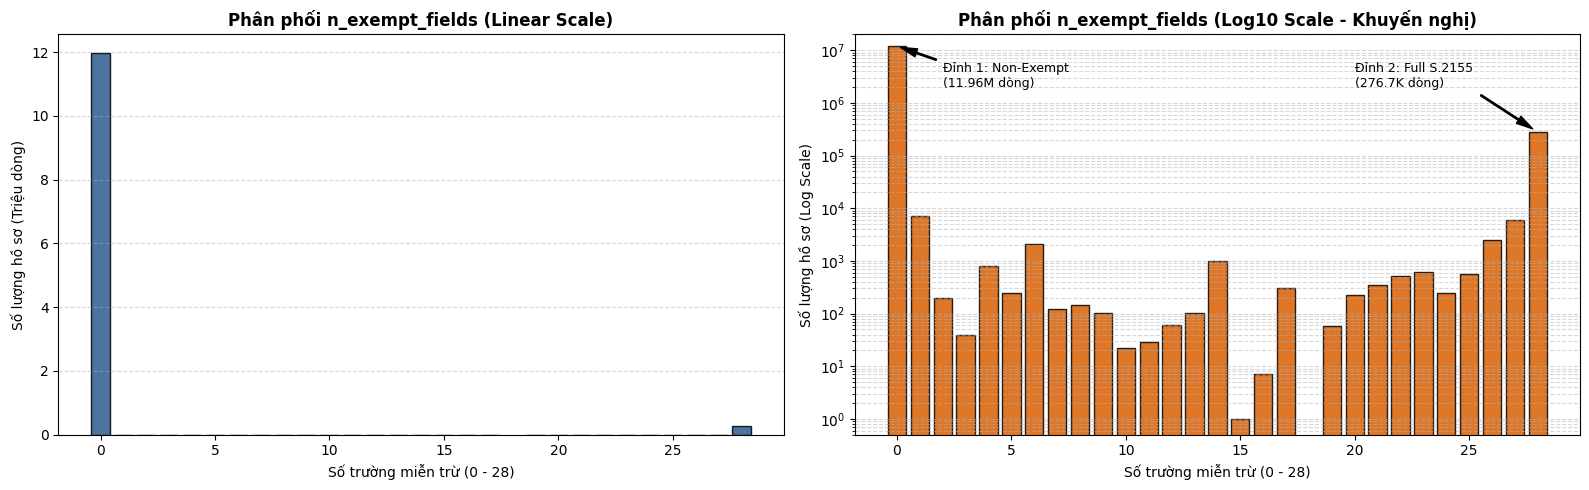

In [69]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Linear Scale (Thấy tỷ lệ áp đảo của n=0)
ax1.bar(x09_df['n_exempt_fields'], x09_df['raw_count'] / 1e6, color='#2b5c8f', edgecolor='black', alpha=0.85)
ax1.set_title('Phân phối n_exempt_fields (Linear Scale)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Số trường miễn trừ (0 - 28)', fontsize=10)
ax1.set_ylabel('Số lượng hồ sơ (Triệu dòng)', fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Subplot 2: Log Scale (BẮT BUỘC - Thấy rõ cấu trúc chữ U & 28 bậc)
bars = ax2.bar(x09_df['n_exempt_fields'], x09_df['raw_count'], color='#d95f02', edgecolor='black', alpha=0.85)
ax2.set_yscale('log')
ax2.set_title('Phân phối n_exempt_fields (Log10 Scale - Khuyến nghị)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Số trường miễn trừ (0 - 28)', fontsize=10)
ax2.set_ylabel('Số lượng hồ sơ (Log Scale)', fontsize=10)
ax2.set_ylim(bottom=0.5, top=2e7)
ax2.grid(axis='y', which='both', linestyle='--', alpha=0.5)

# Đánh dấu 2 đỉnh quan trọng
ax2.annotate('Đỉnh 1: Non-Exempt\n(11.96M dòng)', xy=(0, 11959280), xytext=(2, 2e6),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6), fontsize=9)
ax2.annotate('Đỉnh 2: Full S.2155\n(276.7K dòng)', xy=(28, 276755), xytext=(20, 2e6),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6), fontsize=9)

plt.tight_layout()
plt.show()

## Section 4.1: Step B-2.3 — Applicant & Co-Applicant Age Sentinels by `action_taken` (Rule T08)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Cross-tabulate applicant and co-applicant special age codes (`8888` and `9999`) across all `action_taken` outcomes to evaluate behavioral clustering.
  - Calculate `share_of_all_app_8888_pct` and `share_of_all_coapp_8888_pct` to verify that `8888` concentrates overwhelmingly in purchased loans (`action_taken = 6`).
- **Output:** Age sentinel cross-tabulation exported to `output/B05_age_sentinels_crosstab.csv`.

In [53]:
# Step 1: Cross-tabulate applicant and co-applicant special age codes (8888, 9999) by action_taken
age_cross_sql = f"""
SELECT
    TRIM(action_taken) AS action_taken,
    CASE WHEN TRIM(action_taken) = '1' THEN '1 - Loan originated' WHEN TRIM(action_taken) = '2' THEN '2 - Application approved but not accepted' WHEN TRIM(action_taken) = '3' THEN '3 - Application denied' WHEN TRIM(action_taken) = '4' THEN '4 - Application withdrawn by applicant' WHEN TRIM(action_taken) = '5' THEN '5 - File closed for incompleteness' WHEN TRIM(action_taken) = '6' THEN '6 - Loan purchased by institution' WHEN TRIM(action_taken) = '7' THEN '7 - Preapproval request denied' WHEN TRIM(action_taken) = '8' THEN '8 - Preapproval request approved but not accepted' ELSE TRIM(action_taken) END AS action_label,
    COUNT(*)::BIGINT AS total_apps,
    COUNT(*) FILTER (WHERE TRIM(applicant_age) = '8888')::BIGINT AS app_age_8888_count,
    ROUND(COUNT(*) FILTER (WHERE TRIM(applicant_age) = '8888') * 100.0 / (SELECT COUNT(*) FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(applicant_age) = '8888'), 2) AS share_of_all_app_8888_pct,
    COUNT(*) FILTER (WHERE TRIM(co_applicant_age) = '8888')::BIGINT AS coapp_age_8888_count,
    ROUND(COUNT(*) FILTER (WHERE TRIM(co_applicant_age) = '8888') * 100.0 / (SELECT COUNT(*) FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(co_applicant_age) = '8888'), 2) AS share_of_all_coapp_8888_pct,
    COUNT(*) FILTER (WHERE TRIM(co_applicant_age) = '9999')::BIGINT AS coapp_age_9999_count,
    ROUND(COUNT(*) FILTER (WHERE TRIM(co_applicant_age) = '9999') * 100.0 / (SELECT COUNT(*) FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(co_applicant_age) = '9999'), 2) AS share_of_all_coapp_9999_pct
FROM read_parquet('{INPUT_PARQUET.as_posix()}') GROUP BY 1, 2 ORDER BY 1
"""
age_df = duck_conn.execute(age_cross_sql).df()
save_and_log(age_df, 'B05_age_sentinels_crosstab.csv')
display(age_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_age_sentinels_crosstab.csv | Size: 0.79 KB (806 bytes) | Shape: (8, 9)


,action_taken,action_label,total_apps,app_age_8888_count,share_of_all_app_8888_pct,coapp_age_8888_count,share_of_all_coapp_8888_pct,coapp_age_9999_count,share_of_all_coapp_9999_pct
0,1,1 - Loan originated,6197085,188669,12.89,63829,5.41,3402056,51.03
1,2,2 - Application approved but not accepted,361232,7932,0.54,2555,0.22,231660,3.48
2,3,3 - Application denied,2103462,30811,2.11,10629,0.90,1423392,21.35
3,4,4 - Application withdrawn by applicant,1538273,45958,3.14,23681,2.01,931647,13.98
4,5,5 - File closed for incompleteness,581940,4084,0.28,1562,0.13,390817,5.86
5,6,6 - Loan purchased by institution,1276504,1185349,80.98,1076382,91.30,164455,2.47
6,7,7 - Preapproval request denied,47312,343,0.02,92,0.01,30766,0.46
7,8,8 - Preapproval request approved but not accepted,153391,538,0.04,225,0.02,91609,1.37


## Section 4.2a: Step B-2.3 — Undocumented Co-Applicant Values Audit (Rule X05)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Audit all values in `co_applicant_age`, `co_applicant_sex`, `co_applicant_race_1`, and `co_applicant_ethnicity_1` against Data Dictionary `Allowed Values`.
  - In raw data, `co_applicant_race_1` has 1,014 blank `""` rows and `co_applicant_ethnicity_1` has 1,463 blank `""` rows (as of run 2026-10-31, cell 17). In Pandas post-T01, these become `NaN`/`NULL`. The rule explicitly handles `NULL` alongside blank `''` and sets status to `NA` [Hypothesis: unclassified or free-form text co-applicant].
- **Output:** Exported `output/B05_coapplicant_undocumented_values.csv`.

In [54]:
# Step 1: Define explicit valid code tuples from Data Dictionary and audit any values outside Allowed Values
AGE_PRES, SEX_PRES = "('<25', '25-34', '35-44', '45-54', '55-64', '65-74', '>74')", "('1', '2', '3', '6')"
RACE_PRES = "('1', '2', '21', '22', '23', '24', '25', '26', '27', '3', '4', '41', '42', '43', '44', '5', '6')"
ETH_PRES = "('1', '11', '12', '13', '14', '2', '3')"

undoc_coapp_sql = f"""
SELECT 'co_applicant_age' AS col, TRIM(co_applicant_age) AS raw_val, COUNT(*)::BIGINT AS cnt FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(co_applicant_age) NOT IN {AGE_PRES[:-1]}, '8888', '9999') GROUP BY 1, 2
UNION ALL SELECT 'co_applicant_sex', TRIM(co_applicant_sex), COUNT(*)::BIGINT FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(co_applicant_sex) NOT IN ('1','2','3','4','5','6') GROUP BY 1, 2
UNION ALL SELECT 'co_applicant_race_1', TRIM(co_applicant_race_1), COUNT(*)::BIGINT FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(co_applicant_race_1) NOT IN {RACE_PRES[:-1]}, '7', '8') GROUP BY 1, 2
UNION ALL SELECT 'co_applicant_ethnicity_1', TRIM(co_applicant_ethnicity_1), COUNT(*)::BIGINT FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(co_applicant_ethnicity_1) NOT IN {ETH_PRES[:-1]}, '4', '5') GROUP BY 1, 2
"""
undoc_coapp_df = duck_conn.execute(undoc_coapp_sql).df()
save_and_log(undoc_coapp_df, 'B05_coapplicant_undocumented_values.csv')
display(undoc_coapp_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_coapplicant_undocumented_values.csv | Size: 0.07 KB (76 bytes) | Shape: (2, 3)


,col,raw_val,cnt
0,co_applicant_race_1,,1014
1,co_applicant_ethnicity_1,,1463


## Section 4.2b: Step B-2.3 — 4-State Co-Applicant Classification & Discordance Resolution (Rule X05)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Classify each field into 4 explicit states: `Present`, `No_Coapp`, `NA`, and `Invalid` (verifying 0 `Invalid` values).
  - Resolve discordant combinations using hierarchical precedence: `Present > No_Coapp > NA`. If any field indicates a co-applicant is present, `has_coapplicant = 1`; if consensus indicates absence, `has_coapplicant = 0`; if all 4 are NA, `has_coapplicant = NULL`.
  - Track `flag_coapp_discordant = True` on 79,088 raw rows (18,230 in S0, as of run 2026-10-31, cell 19).
  - Empirical resolution: In Analytic Sample $S0$, only 3,625 rows (0.045%, as of run 2026-10-31, cell 19) remain all-NA (`has_coapplicant = NULL`).
  - Stale count calibration: `co_applicant_age = '8888'` with three `No_Coapp` accounts for 14,099 rows (1,771 in S0, as of run 2026-10-31, cell 19). `co_applicant_age = '8888'` with three `NA` accounts for 1,134,611 rows (1,042,618 in purchased loans; only 3,625 in S0, as of run 2026-10-31, cell 19). Overall, 91.30% of all `co_applicant_age = '8888'` are concentrated in purchased loans (`action_taken = 6`, as of run 2026-10-31, cell 15).
- **Output:** Exported `output/B05_coapplicant_agreement.csv`.

In [55]:
# Step 1: Classify into 4 explicit states (handling NULL/blank on race_1/eth_1 as 'NA') and assert 0 Invalid codes
coapp_4state_sql = f"""
WITH states AS (
    SELECT
        CASE WHEN TRIM(co_applicant_age) IN {AGE_PRES} THEN 'Present' WHEN TRIM(co_applicant_age) = '9999' THEN 'No_Coapp'
             WHEN TRIM(co_applicant_age) = '8888' THEN 'NA' ELSE 'Invalid' END AS age_st,
        CASE WHEN TRIM(co_applicant_sex) IN {SEX_PRES} THEN 'Present' WHEN TRIM(co_applicant_sex) = '5' THEN 'No_Coapp'
             WHEN TRIM(co_applicant_sex) = '4' THEN 'NA' ELSE 'Invalid' END AS sex_st,
        CASE WHEN TRIM(co_applicant_race_1) IN {RACE_PRES} THEN 'Present' WHEN TRIM(co_applicant_race_1) = '8' THEN 'No_Coapp'
             WHEN TRIM(co_applicant_race_1) IN ('7', '') OR co_applicant_race_1 IS NULL THEN 'NA' ELSE 'Invalid' END AS race_st,
        CASE WHEN TRIM(co_applicant_ethnicity_1) IN {ETH_PRES} THEN 'Present' WHEN TRIM(co_applicant_ethnicity_1) = '5' THEN 'No_Coapp'
             WHEN TRIM(co_applicant_ethnicity_1) IN ('4', '') OR co_applicant_ethnicity_1 IS NULL THEN 'NA' ELSE 'Invalid' END AS eth_st,
        {S0_SQL_PRED} AS in_s0, (TRIM(action_taken) = '6') AS is_purchased
    FROM read_parquet('{INPUT_PARQUET.as_posix()}')
)
SELECT age_st, sex_st, race_st, eth_st,
       CASE WHEN 'Invalid' IN (age_st, sex_st, race_st, eth_st) THEN 'ERROR_INVALID'
            WHEN 'Present' IN (age_st, sex_st, race_st, eth_st) THEN '1 (Has Co-Applicant)'
            WHEN 'No_Coapp' IN (age_st, sex_st, race_st, eth_st) THEN '0 (No Co-Applicant)'
            ELSE 'NULL (Not Applicable: All 4 = NA)' END AS x05_assigned_value,
       (NOT (age_st = sex_st AND sex_st = race_st AND race_st = eth_st)) AS is_discordant,
       COUNT(*)::BIGINT AS raw_count, ROUND(COUNT(*) * 100.0 / {total_raw_rows}, 4) AS raw_share_pct,
       COUNT(*) FILTER (WHERE in_s0)::BIGINT AS s0_count,
       COUNT(*) FILTER (WHERE is_purchased)::BIGINT AS purchased_count
FROM states GROUP BY 1, 2, 3, 4, 5, 6 ORDER BY raw_count DESC
"""
coapp_full_df = duck_conn.execute(coapp_4state_sql).df()
assert coapp_full_df['raw_count'].sum() == total_raw_rows and (coapp_full_df['x05_assigned_value'] == 'ERROR_INVALID').sum() == 0
all_na_purchased = int(coapp_full_df.loc[coapp_full_df['x05_assigned_value'].str.startswith('NULL'), 'purchased_count'].iloc[0])
coapp_df = coapp_full_df.drop(columns=['purchased_count'])
save_and_log(coapp_df, 'B05_coapplicant_agreement.csv')
display(coapp_df.head(10))
tot_discordant_raw = int(coapp_df.loc[coapp_df['is_discordant'], 'raw_count'].sum())
tot_discordant_s0 = int(coapp_df.loc[coapp_df['is_discordant'], 's0_count'].sum())
tot_all_na_raw = int(coapp_df.loc[coapp_df['x05_assigned_value'].str.startswith('NULL'), 'raw_count'].sum())
tot_all_na_s0 = int(coapp_df.loc[coapp_df['x05_assigned_value'].str.startswith('NULL'), 's0_count'].sum())
tot_s0_coapp = int(coapp_df['s0_count'].sum())
print(f"Rule X05 | Discordant Raw: {tot_discordant_raw:,} ({tot_discordant_raw*100.0/total_raw_rows:.2f}%), S0: {tot_discordant_s0:,} ({tot_discordant_s0*100.0/tot_s0_coapp:.2f}%) | All-NA Raw: {tot_all_na_raw:,} (Purchased: {all_na_purchased:,}; S0: {tot_all_na_s0:,}, {tot_all_na_s0*100.0/tot_s0_coapp:.3f}%)")

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_coapplicant_agreement.csv | Size: 4.16 KB (4,263 bytes) | Shape: (62, 9)


,age_st,sex_st,race_st,eth_st,x05_assigned_value,is_discordant,raw_count,raw_share_pct,s0_count
0,No_Coapp,No_Coapp,No_Coapp,No_Coapp,0 (No Co-Applicant),False,6638684,54.1527,4699893
1,Present,Present,Present,Present,1 (Has Co-Applicant),False,4406816,35.9470,3414916
2,NA,NA,NA,NA,NULL (Not Applicable: All 4 = NA),False,1134611,9.2552,3625
3,NA,Present,Present,Present,1 (Has Co-Applicant),True,16892,0.1378,1113
4,NA,No_Coapp,No_Coapp,No_Coapp,0 (No Co-Applicant),True,14099,0.1150,1771
5,NA,NA,NA,No_Coapp,0 (No Co-Applicant),True,6856,0.0559,3
6,No_Coapp,No_Coapp,No_Coapp,NA,0 (No Co-Applicant),True,5896,0.0481,244
7,No_Coapp,NA,NA,NA,0 (No Co-Applicant),True,5774,0.0471,0
8,NA,NA,NA,Present,1 (Has Co-Applicant),True,5473,0.0446,12
9,No_Coapp,NA,Present,NA,1 (Has Co-Applicant),True,3676,0.0300,2500


Rule X05 | Discordant Raw: 79,088 (0.65%), S0: 18,230 (0.22%) | All-NA Raw: 1,134,611 (Purchased: 1,042,618; S0: 3,625, 0.045%)


## Section 5.1: Step B-2.4 — Sequential NULL-Safe Analytic Sample Waterfall & Separate Memo Table (Rules F01–F03)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Verify and assert that the exact value domain of `business_or_commercial_purpose` and `reverse_mortgage` across all 12.26M rows is strictly `{'1', '2', '1111'}` (0 out-of-domain tokens, blanks, or NULLs).
  - Build the sequential sample waterfall implementing **Rules F01, F02, and F03** via positive membership `.isin(['2', '1111'])`:
    1. Raw: 12,259,199 rows.
    2. F01 (`action_taken IN ('1','2','3')`): 8,661,779 applications (as of run 2026-10-31, cell 21).
    3. F02 (`business_or_commercial_purpose IN ('2','1111')`): drops 491,602 rows $\rightarrow$ 8,170,177 remaining (as of run 2026-10-31, cell 21).
    4. F03 (`reverse_mortgage IN ('2','1111')`): drops 33,513 rows $\rightarrow$ **8,136,664 rows** in Analytic Baseline $S0$ (as of run 2026-10-31, cell 21).
  - Verify that the combined sequential drop of F02 & F03 on F01 is exactly **525,115 rows** (491,602 + 33,569 − 56 overlap = 525,115 rows, as of run 2026-10-31, cell 21), and log the exact count of retained code-`1111` rows in $S0$ (**250,691** for F02 and **250,889** for F03, as of run 2026-10-31, cell 21).
- **Output:** Sequential waterfall exported to `output/B05_waterfall_f01_f03.csv` and standalone memo to `output/B05_waterfall_memo_diagnostics.csv`.

In [56]:
# Step 1: Query sequential waterfall levels/deltas, assert {1, 2, 1111} domain, and count retained 1111 in S0
waterfall_sql = f"""
SELECT
    COUNT(*)::BIGINT AS total_raw,
    COUNT(*) FILTER (WHERE TRIM(action_taken) IN ('1', '2', '3'))::BIGINT AS f01_sample,
    COUNT(*) FILTER (WHERE TRIM(action_taken) IN ('1', '2', '3') AND TRIM(business_or_commercial_purpose) IN ('2', '1111'))::BIGINT AS f02_sample,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED})::BIGINT AS s0_sample,
    COUNT(*) FILTER (WHERE TRIM(action_taken) IN ('1', '2', '3') AND TRIM(reverse_mortgage) = '1')::BIGINT AS f03_standalone_on_f01,
    COUNT(*) FILTER (WHERE TRIM(action_taken) IN ('1', '2', '3') AND TRIM(business_or_commercial_purpose) = '1' AND TRIM(reverse_mortgage) = '1')::BIGINT AS f02_f03_overlap_on_f01,
    COUNT(*) FILTER (WHERE TRIM(business_or_commercial_purpose) NOT IN ('1', '2', '1111') OR business_or_commercial_purpose IS NULL)::BIGINT AS f02_out_of_domain,
    COUNT(*) FILTER (WHERE TRIM(reverse_mortgage) NOT IN ('1', '2', '1111') OR reverse_mortgage IS NULL)::BIGINT AS f03_out_of_domain,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND TRIM(business_or_commercial_purpose) = '1111')::BIGINT AS f02_1111_in_s0,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND TRIM(reverse_mortgage) = '1111')::BIGINT AS f03_1111_in_s0
FROM read_parquet('{INPUT_PARQUET.as_posix()}')
"""
wf_res = duck_conn.execute(waterfall_sql).fetchone()
tot_raw, tot_f01, tot_f02, tot_analytic = wf_res[0], wf_res[1], wf_res[2], wf_res[3]
tot_f03_standalone, overlap, f02_ood, f03_ood, f02_1111_s0, f03_1111_s0 = wf_res[4:]

assert tot_f01 - tot_analytic == 525115, f"Waterfall discrepancy: {tot_f01 - tot_analytic}"
assert f02_ood == 0 and f03_ood == 0, f"Out-of-domain tokens in F02/F03: f02={f02_ood}, f03={f03_ood}"

# Step 2: Format and export sequential waterfall and memo tables (including D-A code-1111 counts in S0)
waterfall_df = pd.DataFrame([
    {'Step': 'Raw Applications', 'Criteria': 'All 2024 HMDA records', 'Applications': tot_raw, 'Excluded': 0, 'Retention_of_Raw_Pct': 100.0},
    {'Step': 'Rule F01 (Decision Sample)', 'Criteria': "action_taken IN ('1','2','3')", 'Applications': tot_f01, 'Excluded': tot_raw - tot_f01, 'Retention_of_Raw_Pct': round(tot_f01 * 100.0 / tot_raw, 2)},
    {'Step': 'Rule F02 (Consumer Purpose)', 'Criteria': "business_or_commercial_purpose IN ('2','1111')", 'Applications': tot_f02, 'Excluded': tot_f01 - tot_f02, 'Retention_of_Raw_Pct': round(tot_f02 * 100.0 / tot_raw, 2)},
    {'Step': 'Rule F03 (Analytic Baseline S0)', 'Criteria': "reverse_mortgage IN ('2','1111')", 'Applications': tot_analytic, 'Excluded': tot_f02 - tot_analytic, 'Retention_of_Raw_Pct': round(tot_analytic * 100.0 / tot_raw, 2)}
])
memo_df = pd.DataFrame([
    {'Metric': 'F02 Exclusion Alone on F01', 'Rows': tot_f01 - tot_f02, 'Pct_of_F01': round((tot_f01 - tot_f02) * 100.0 / tot_f01, 4)},
    {'Metric': 'F03 Exclusion Alone on F01', 'Rows': tot_f03_standalone, 'Pct_of_F01': round(tot_f03_standalone * 100.0 / tot_f01, 4)},
    {'Metric': 'F02 & F03 Overlap on F01', 'Rows': overlap, 'Pct_of_F01': round(overlap * 100.0 / tot_f01, 6)},
    {'Metric': 'Total Combined (F02 + F03 Excluded)', 'Rows': tot_f01 - tot_analytic, 'Pct_of_F01': round((tot_f01 - tot_analytic) * 100.0 / tot_f01, 4)},
    {'Metric': "F02 Exempt ('1111') Retained in S0", 'Rows': f02_1111_s0, 'Pct_of_F01': round(f02_1111_s0 * 100.0 / tot_f01, 4)},
    {'Metric': "F03 Exempt ('1111') Retained in S0", 'Rows': f03_1111_s0, 'Pct_of_F01': round(f03_1111_s0 * 100.0 / tot_f01, 4)}
])
save_and_log(waterfall_df, 'B05_waterfall_f01_f03.csv'); save_and_log(memo_df, 'B05_waterfall_memo_diagnostics.csv')
display(waterfall_df); display(memo_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_waterfall_f01_f03.csv | Size: 0.38 KB (384 bytes) | Shape: (4, 5)
Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_waterfall_memo_diagnostics.csv | Size: 0.29 KB (296 bytes) | Shape: (6, 3)


,Step,Criteria,Applications,Excluded,Retention_of_Raw_Pct
0,Raw Applications,All 2024 HMDA records,12259199,0,100.00
1,Rule F01 (Decision Sample),"action_taken IN ('1','2','3')",8661779,3597420,70.66
2,Rule F02 (Consumer Purpose),"business_or_commercial_purpose IN ('2','1111')",8170177,491602,66.65
3,Rule F03 (Analytic Baseline S0),"reverse_mortgage IN ('2','1111')",8136664,33513,66.37


,Metric,Rows,Pct_of_F01
0,F02 Exclusion Alone on F01,491602,5.675500
1,F03 Exclusion Alone on F01,33569,0.387600
2,F02 & F03 Overlap on F01,56,0.000647
3,Total Combined (F02 + F03 Excluded),525115,6.062400
4,F02 Exempt ('1111') Retained in S0,250691,2.894200
5,F03 Exempt ('1111') Retained in S0,250889,2.896500


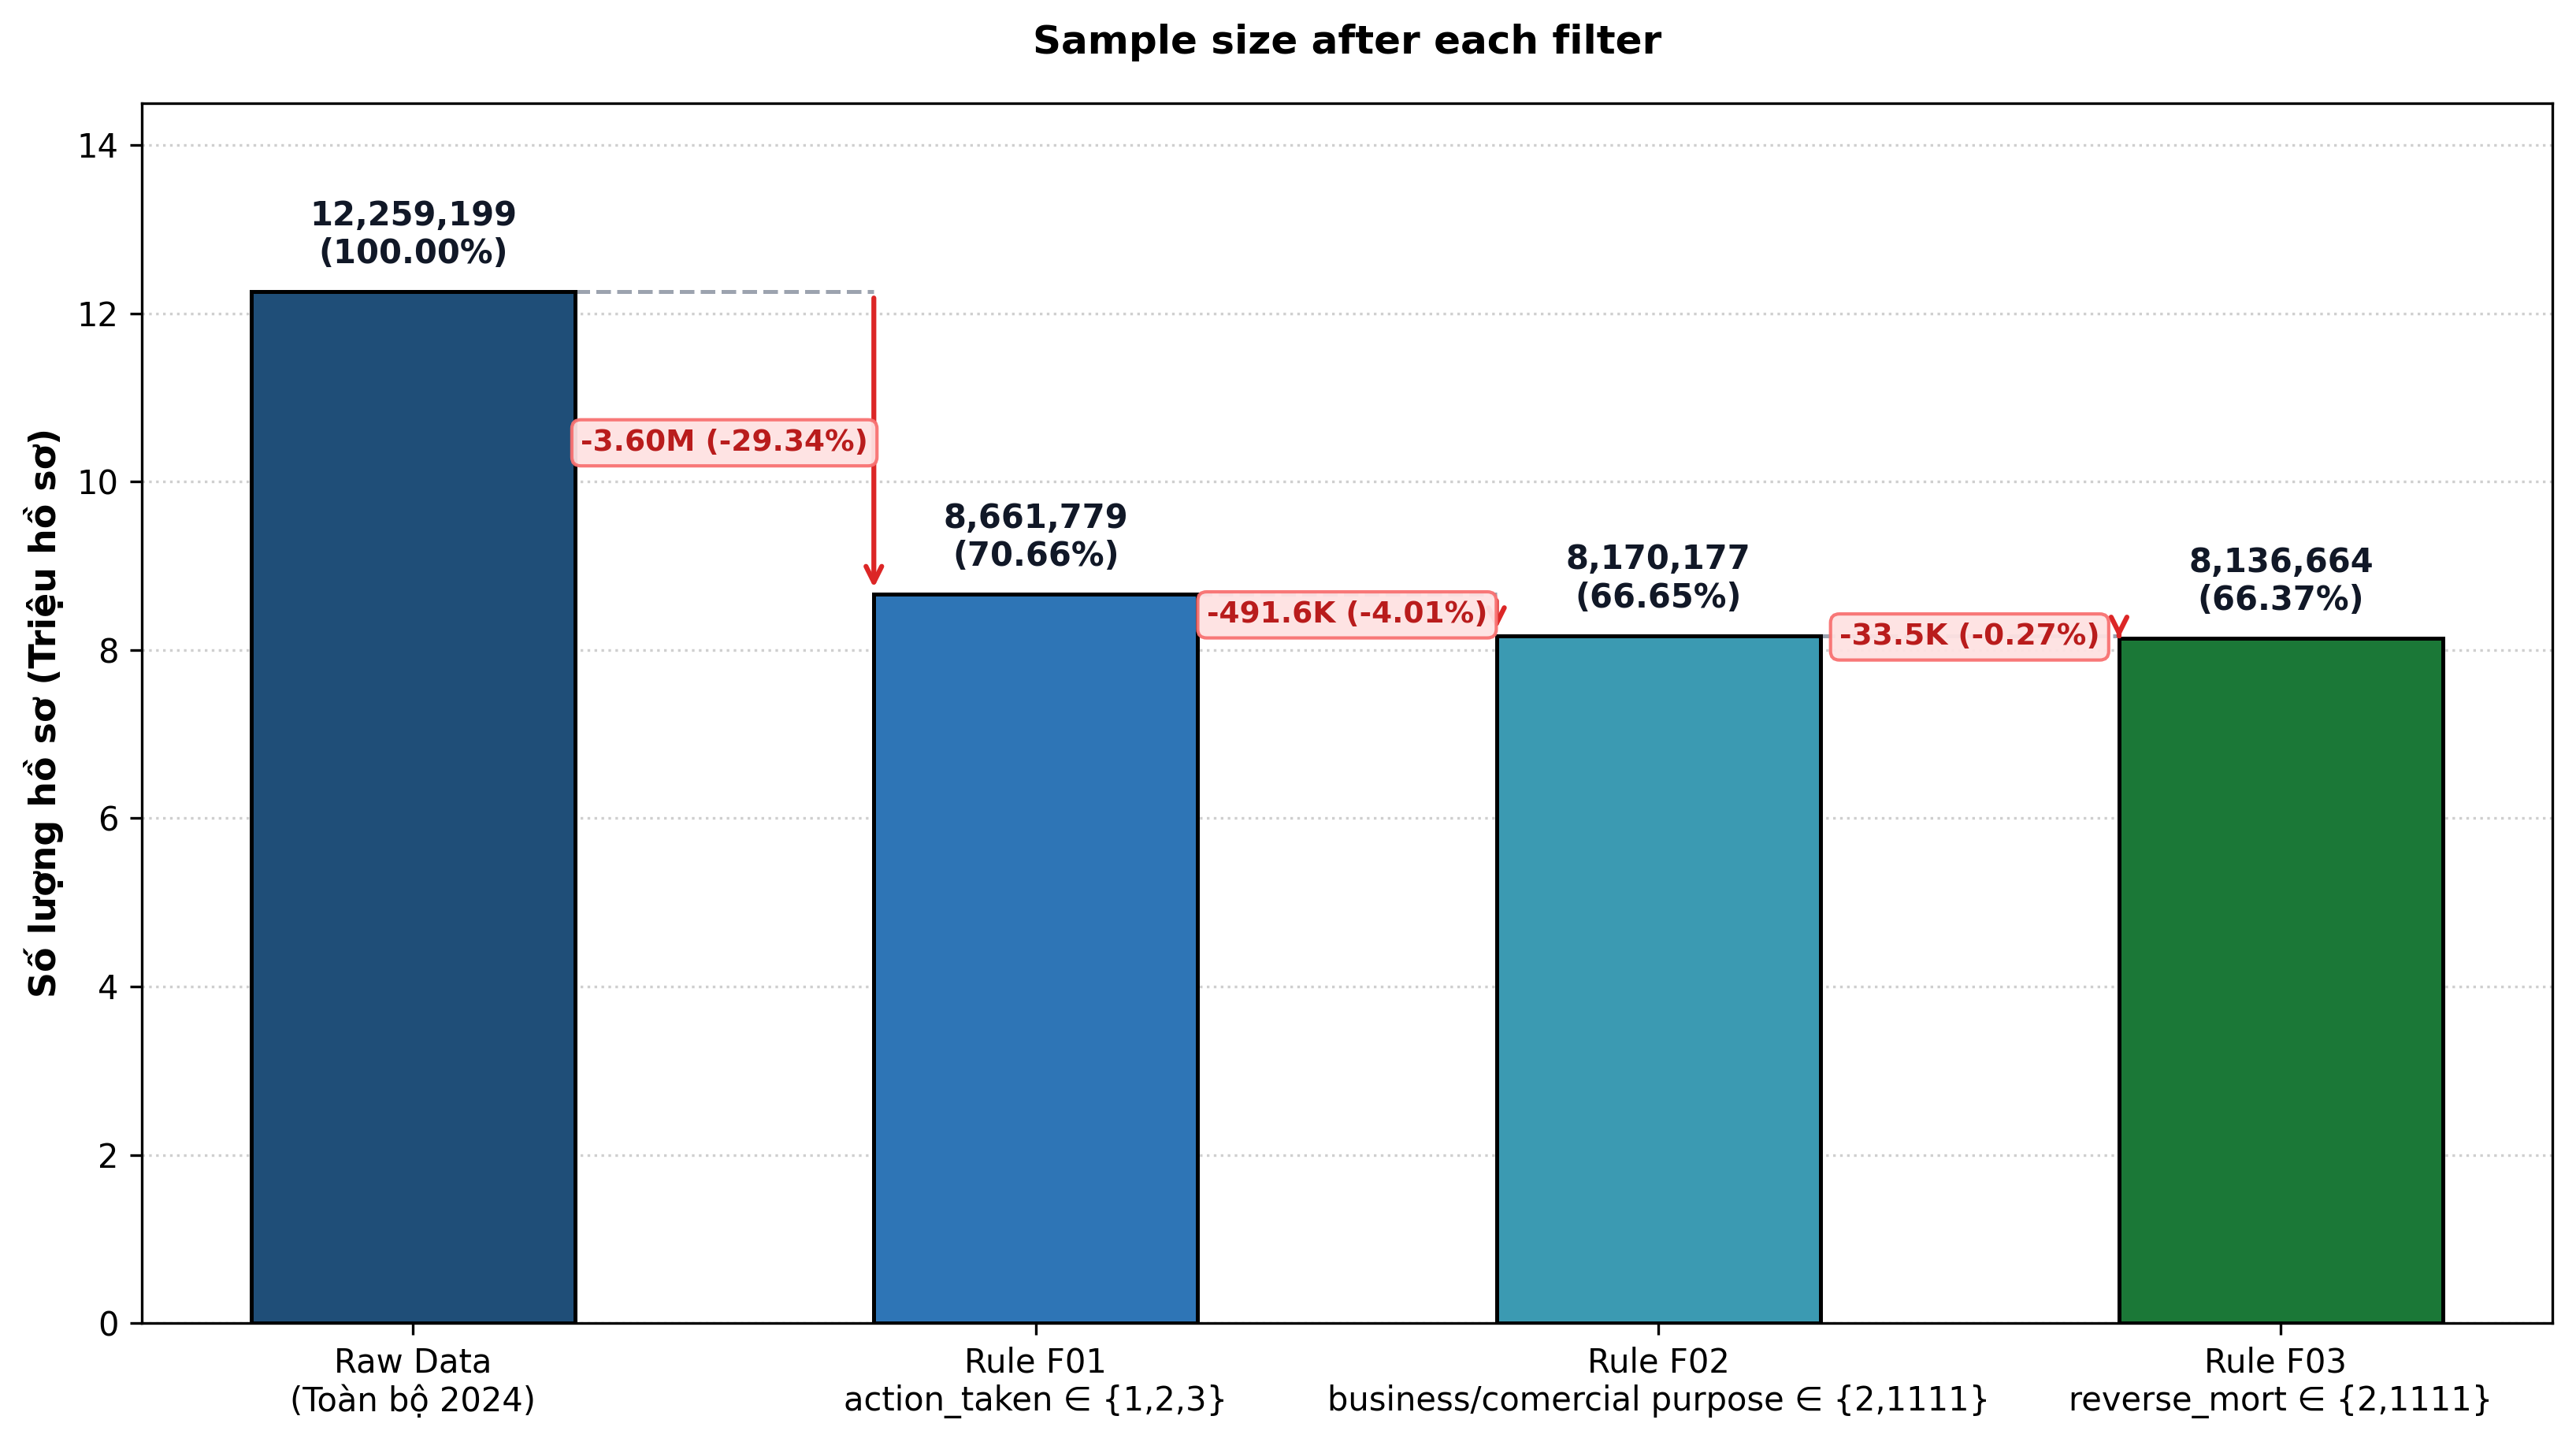

In [71]:
import matplotlib.pyplot as plt

# Step 1: Chuẩn bị dữ liệu và nhãn các bước lọc
wf_df = pd.read_csv(OUTPUT_DIR / 'B05_waterfall_f01_f03.csv')
steps = ['Raw Data\n(Toàn bộ 2024)', 'Rule F01\naction_taken ∈ {1,2,3}',
         'Rule F02\nbusiness/comercial purpose ∈ {2,1111}', 'Rule F03 \nreverse_mort ∈ {2,1111}']
apps_m = wf_df['Applications'].values / 1e6

fig, ax = plt.subplots(figsize=(11, 6.2), dpi=300)
colors = ['#1f4e78', '#2e75b6', '#3b9ab2', '#1b7837']
bars = ax.bar(range(4), apps_m, color=colors, width=0.52, edgecolor='black', linewidth=1.2, zorder=3)

# Step 2: Gắn nhãn số lượng và % giữ lại trên đỉnh cột
for b, val, pct in zip(bars, wf_df['Applications'], wf_df['Retention_of_Raw_Pct']):
    ax.text(b.get_x() + b.get_width()/2., b.get_height() + 0.25, f'{val:,.0f}\n({pct:.2f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold', color='#111827')

# Step 3: Vẽ đường cầu nối bậc thang và badge loại trừ màu đỏ giữa các cột
for i in range(3):
    x1, x2 = bars[i].get_x() + bars[i].get_width(), bars[i+1].get_x()
    y_prev, y_curr = apps_m[i], apps_m[i+1]
    drop_val = wf_df['Excluded'].iloc[i+1]
    drop_str = f'-{drop_val/1e6:.2f}M (-{drop_val*100.0/wf_df["Applications"].iloc[0]:.2f}%)' if drop_val >= 1e6 else f'-{drop_val/1e3:,.1f}K (-{drop_val*100.0/wf_df["Applications"].iloc[0]:.2f}%)'
    
    ax.plot([x1, x2], [y_prev, y_prev], color='#9ca3af', linestyle='--', linewidth=1.2, zorder=2)
    ax.annotate('', xy=(x2, y_curr), xytext=(x2, y_prev), arrowprops=dict(arrowstyle='->', color='#dc2626', lw=1.5, mutation_scale=12))
    ax.text((x1 + x2)/2, (y_prev + y_curr)/2, drop_str, ha='center', va='center', fontsize=9, fontweight='semibold', color='#b91c1c',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#fee2e2', edgecolor='#f87171', alpha=0.95), zorder=4)

ax.set_xticks(range(4)); ax.set_xticklabels(steps, fontsize=10, fontweight='medium')
ax.set_ylabel('Số lượng hồ sơ (Triệu hồ sơ)', fontsize=11, fontweight='bold')
ax.set_ylim(0, 14.5); ax.grid(axis='y', linestyle=':', alpha=0.6, zorder=0); ax.set_axisbelow(True)
ax.set_title('Sample size after each filter', fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'B05_figure_2_waterfall.png', dpi=300)
plt.show()

## Section 5.2: Step B-2.4 — Numeric Range Validity Audit in Raw vs. Analytic Sample (Rules V01–V05)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Audit Rules V01 through V05 across both **Full Raw (12.26M)** and **Analytic Sample S0 (8.14M)**.
  - Assert exact agreement with previously locked B04 and B05 baseline counts for V01 (`loan_amount <= 0`), V02 (`income <= 0`), V03 (`CLTV <= 0 | > 200`), V04 (`interest_rate <= 0 | > 25%`), and V05 (`loan_term < 1 | > 480`).
- **Output:** Range validity profile exported to `output/B05_validity_in_analytic_sample.csv`.

In [57]:
# Step 1: Query V01-V05 range violation counts across Full Raw and Analytic Sample S0
v_rules_sql = f"""
SELECT
    COUNT(*) FILTER (WHERE UPPER(TRIM(loan_amount)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(loan_amount) AS DOUBLE) <= 0)::BIGINT AS v01_raw,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND UPPER(TRIM(loan_amount)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(loan_amount) AS DOUBLE) <= 0)::BIGINT AS v01_s0,
    COUNT(*) FILTER (WHERE UPPER(TRIM(income)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(income) AS DOUBLE) <= 0)::BIGINT AS v02_raw,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND UPPER(TRIM(income)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(income) AS DOUBLE) <= 0)::BIGINT AS v02_s0,
    COUNT(*) FILTER (WHERE UPPER(TRIM(combined_loan_to_value_ratio)) NOT IN {SENTINELS_NUM} AND (try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) <= 0 OR try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) > 200))::BIGINT AS v03_raw,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND UPPER(TRIM(combined_loan_to_value_ratio)) NOT IN {SENTINELS_NUM} AND (try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) <= 0 OR try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) > 200))::BIGINT AS v03_s0,
    COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND (try_cast(TRIM(interest_rate) AS DOUBLE) <= 0 OR try_cast(TRIM(interest_rate) AS DOUBLE) > 25))::BIGINT AS v04_raw,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND (try_cast(TRIM(interest_rate) AS DOUBLE) <= 0 OR try_cast(TRIM(interest_rate) AS DOUBLE) > 25))::BIGINT AS v04_s0,
    COUNT(*) FILTER (WHERE UPPER(TRIM(loan_term)) NOT IN {SENTINELS_NUM} AND (try_cast(TRIM(loan_term) AS DOUBLE) < 1 OR try_cast(TRIM(loan_term) AS DOUBLE) > 480))::BIGINT AS v05_raw,
    COUNT(*) FILTER (WHERE {S0_SQL_PRED} AND UPPER(TRIM(loan_term)) NOT IN {SENTINELS_NUM} AND (try_cast(TRIM(loan_term) AS DOUBLE) < 1 OR try_cast(TRIM(loan_term) AS DOUBLE) > 480))::BIGINT AS v05_s0
FROM read_parquet('{INPUT_PARQUET.as_posix()}')
"""
v_res = duck_conn.execute(v_rules_sql).fetchone()
v_range_df = pd.DataFrame([
    {'Rule_ID': 'V01', 'Field': 'loan_amount', 'Condition': '<= 0', 'Raw_Count': v_res[0], 'S0_Count': v_res[1]},
    {'Rule_ID': 'V02', 'Field': 'income', 'Condition': '<= 0', 'Raw_Count': v_res[2], 'S0_Count': v_res[3]},
    {'Rule_ID': 'V03', 'Field': 'combined_loan_to_value_ratio', 'Condition': '<= 0 or > 200', 'Raw_Count': v_res[4], 'S0_Count': v_res[5]},
    {'Rule_ID': 'V04', 'Field': 'interest_rate', 'Condition': '<= 0 or > 25', 'Raw_Count': v_res[6], 'S0_Count': v_res[7]},
    {'Rule_ID': 'V05', 'Field': 'loan_term', 'Condition': '< 1 or > 480', 'Raw_Count': v_res[8], 'S0_Count': v_res[9]}
])
save_and_log(v_range_df, 'B05_validity_in_analytic_sample.csv')
display(v_range_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_validity_in_analytic_sample.csv | Size: 0.23 KB (238 bytes) | Shape: (5, 5)


,Rule_ID,Field,Condition,Raw_Count,S0_Count
0,V01,loan_amount,<= 0,0,0
1,V02,income,<= 0,165254,91261
2,V03,combined_loan_to_value_ratio,<= 0 or > 200,5323,4026
3,V04,interest_rate,<= 0 or > 25,83443,60717
4,V05,loan_term,< 1 or > 480,2893,18


## Section 5.3: Step B-2.4 — `income <= 0` (Rule V02) Cross-Tabulated by `action_taken`

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Cross-tabulate `income` categories (`NA/Exempt`, `Income == 0`, `Income < 0`, and `Income > 0`) against `action_taken` to verify why non-positive incomes concentrate in denied applications.
- **Output:** Income breakdown table exported to `output/B05_v02_income_by_action.csv`.

In [58]:
# Step 1: Cross-tabulate income status (NA, == 0, < 0, > 0) across action_taken
v02_sql = f"""
SELECT
    TRIM(action_taken) AS action_taken,
    COUNT(*)::BIGINT AS total_apps,
    COUNT(*) FILTER (WHERE UPPER(TRIM(income)) IN {SENTINELS_NUM})::BIGINT AS income_na_count,
    COUNT(*) FILTER (WHERE UPPER(TRIM(income)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(income) AS DOUBLE) = 0)::BIGINT AS income_zero_count,
    COUNT(*) FILTER (WHERE UPPER(TRIM(income)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(income) AS DOUBLE) < 0)::BIGINT AS income_negative_count,
    COUNT(*) FILTER (WHERE UPPER(TRIM(income)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(income) AS DOUBLE) > 0)::BIGINT AS income_positive_count
FROM read_parquet('{INPUT_PARQUET.as_posix()}') GROUP BY 1 ORDER BY 1
"""
v02_df = duck_conn.execute(v02_sql).df()
v02_df['share_of_neg_income_pct'] = round(v02_df['income_negative_count'] * 100.0 / v02_df['income_negative_count'].sum(), 2)
save_and_log(v02_df, 'B05_v02_income_by_action.csv')
display(v02_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_v02_income_by_action.csv | Size: 0.41 KB (423 bytes) | Shape: (8, 7)


,action_taken,total_apps,income_na_count,income_zero_count,income_negative_count,income_positive_count,share_of_neg_income_pct
0,1,6197085,417071,53962,345,5725707,4.45
1,2,361232,37643,6898,31,316660,0.40
2,3,2103462,90807,55481,6844,1950330,88.20
3,4,1538273,110399,27962,277,1399635,3.57
4,5,581940,40167,10658,115,531000,1.48
5,6,1276504,1082758,910,0,192836,0.00
6,7,47312,671,997,142,45502,1.83
7,8,153391,918,626,6,151841,0.08


## Section 6.1: Step B-2.5 — Zero-Rate Loans by Lien Status & `action_taken` Outcome Audit (Rule V04 & Decision D-C)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Audit Rule V04 (`interest_rate <= 0`) by `lien_status` across both Full Raw and Analytic Sample $S0$.
  - Audit `interest_rate` reporting across all 8 `action_taken` outcomes to verify whether denied loans report interest rates.
- **Output:** Exported `output/B05_zero_rate_diagnostic.csv` and `output/B05_interest_rate_by_action.csv`.

In [59]:
# Step 1: Breakdown interest_rate <= 0 by lien_status and reconcile with missing_total_count
rate_lien_sql = f"""
SELECT
    TRIM(lien_status) AS lien_status,
    CASE WHEN TRIM(lien_status) = '1' THEN '1 - First Lien' WHEN TRIM(lien_status) = '2' THEN '2 - Subordinate Lien' ELSE TRIM(lien_status) END AS lien_label,
    COUNT(*)::BIGINT AS total_apps,
    COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) IN {SENTINELS_NUM})::BIGINT AS rate_missing_count,
    COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) > 0)::BIGINT AS rate_valid_pos_count,
    COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) <= 0)::BIGINT AS rate_le0_v04_count,
    ROUND(COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) <= 0) * 100.0 /
          (SELECT COUNT(*) FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) <= 0), 2) AS share_of_all_zero_rates_pct,
    ROUND(COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) <= 0) * 100.0 /
          NULLIF(COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) IS NOT NULL), 0), 3) AS zero_rate_pct_of_reported
FROM read_parquet('{INPUT_PARQUET.as_posix()}') GROUP BY 1, 2 ORDER BY 1
"""
rate_lien_df = duck_conn.execute(rate_lien_sql).df()
save_and_log(rate_lien_df, 'B05_zero_rate_diagnostic.csv')

# Step 2: Cross-tabulate interest rate reporting across action_taken
rate_act_sql = f"""
SELECT TRIM(action_taken) AS action_taken, COUNT(*)::BIGINT AS total_apps,
       COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) IN {SENTINELS_NUM})::BIGINT AS rate_missing_count,
       COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) > 0)::BIGINT AS rate_valid_pos_count,
       COUNT(*) FILTER (WHERE UPPER(TRIM(interest_rate)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(interest_rate) AS DOUBLE) <= 0)::BIGINT AS rate_le0_v04_count
FROM read_parquet('{INPUT_PARQUET.as_posix()}') GROUP BY 1 ORDER BY 1
"""
rate_act_df = duck_conn.execute(rate_act_sql).df()
save_and_log(rate_act_df, 'B05_interest_rate_by_action.csv')
display(rate_lien_df); display(rate_act_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_zero_rate_diagnostic.csv | Size: 0.26 KB (271 bytes) | Shape: (2, 8)
Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_interest_rate_by_action.csv | Size: 0.28 KB (286 bytes) | Shape: (8, 5)


,lien_status,lien_label,total_apps,rate_missing_count,rate_valid_pos_count,rate_le0_v04_count,share_of_all_zero_rates_pct,zero_rate_pct_of_reported
0,1,1 - First Lien,9401786,3186504,6211391,3891,4.66,0.063
1,2,2 - Subordinate Lien,2857413,1333391,1444471,79551,95.34,5.220


,action_taken,total_apps,rate_missing_count,rate_valid_pos_count,rate_le0_v04_count
0,1,6197085,222913,5915452,58720
1,2,361232,15605,343201,2426
2,3,2103462,2103462,0,0
3,4,1538273,1538273,0,0
4,5,581940,581940,0,0
5,6,1276504,6270,1248497,21737
6,7,47312,47312,0,0
7,8,153391,4120,148712,559


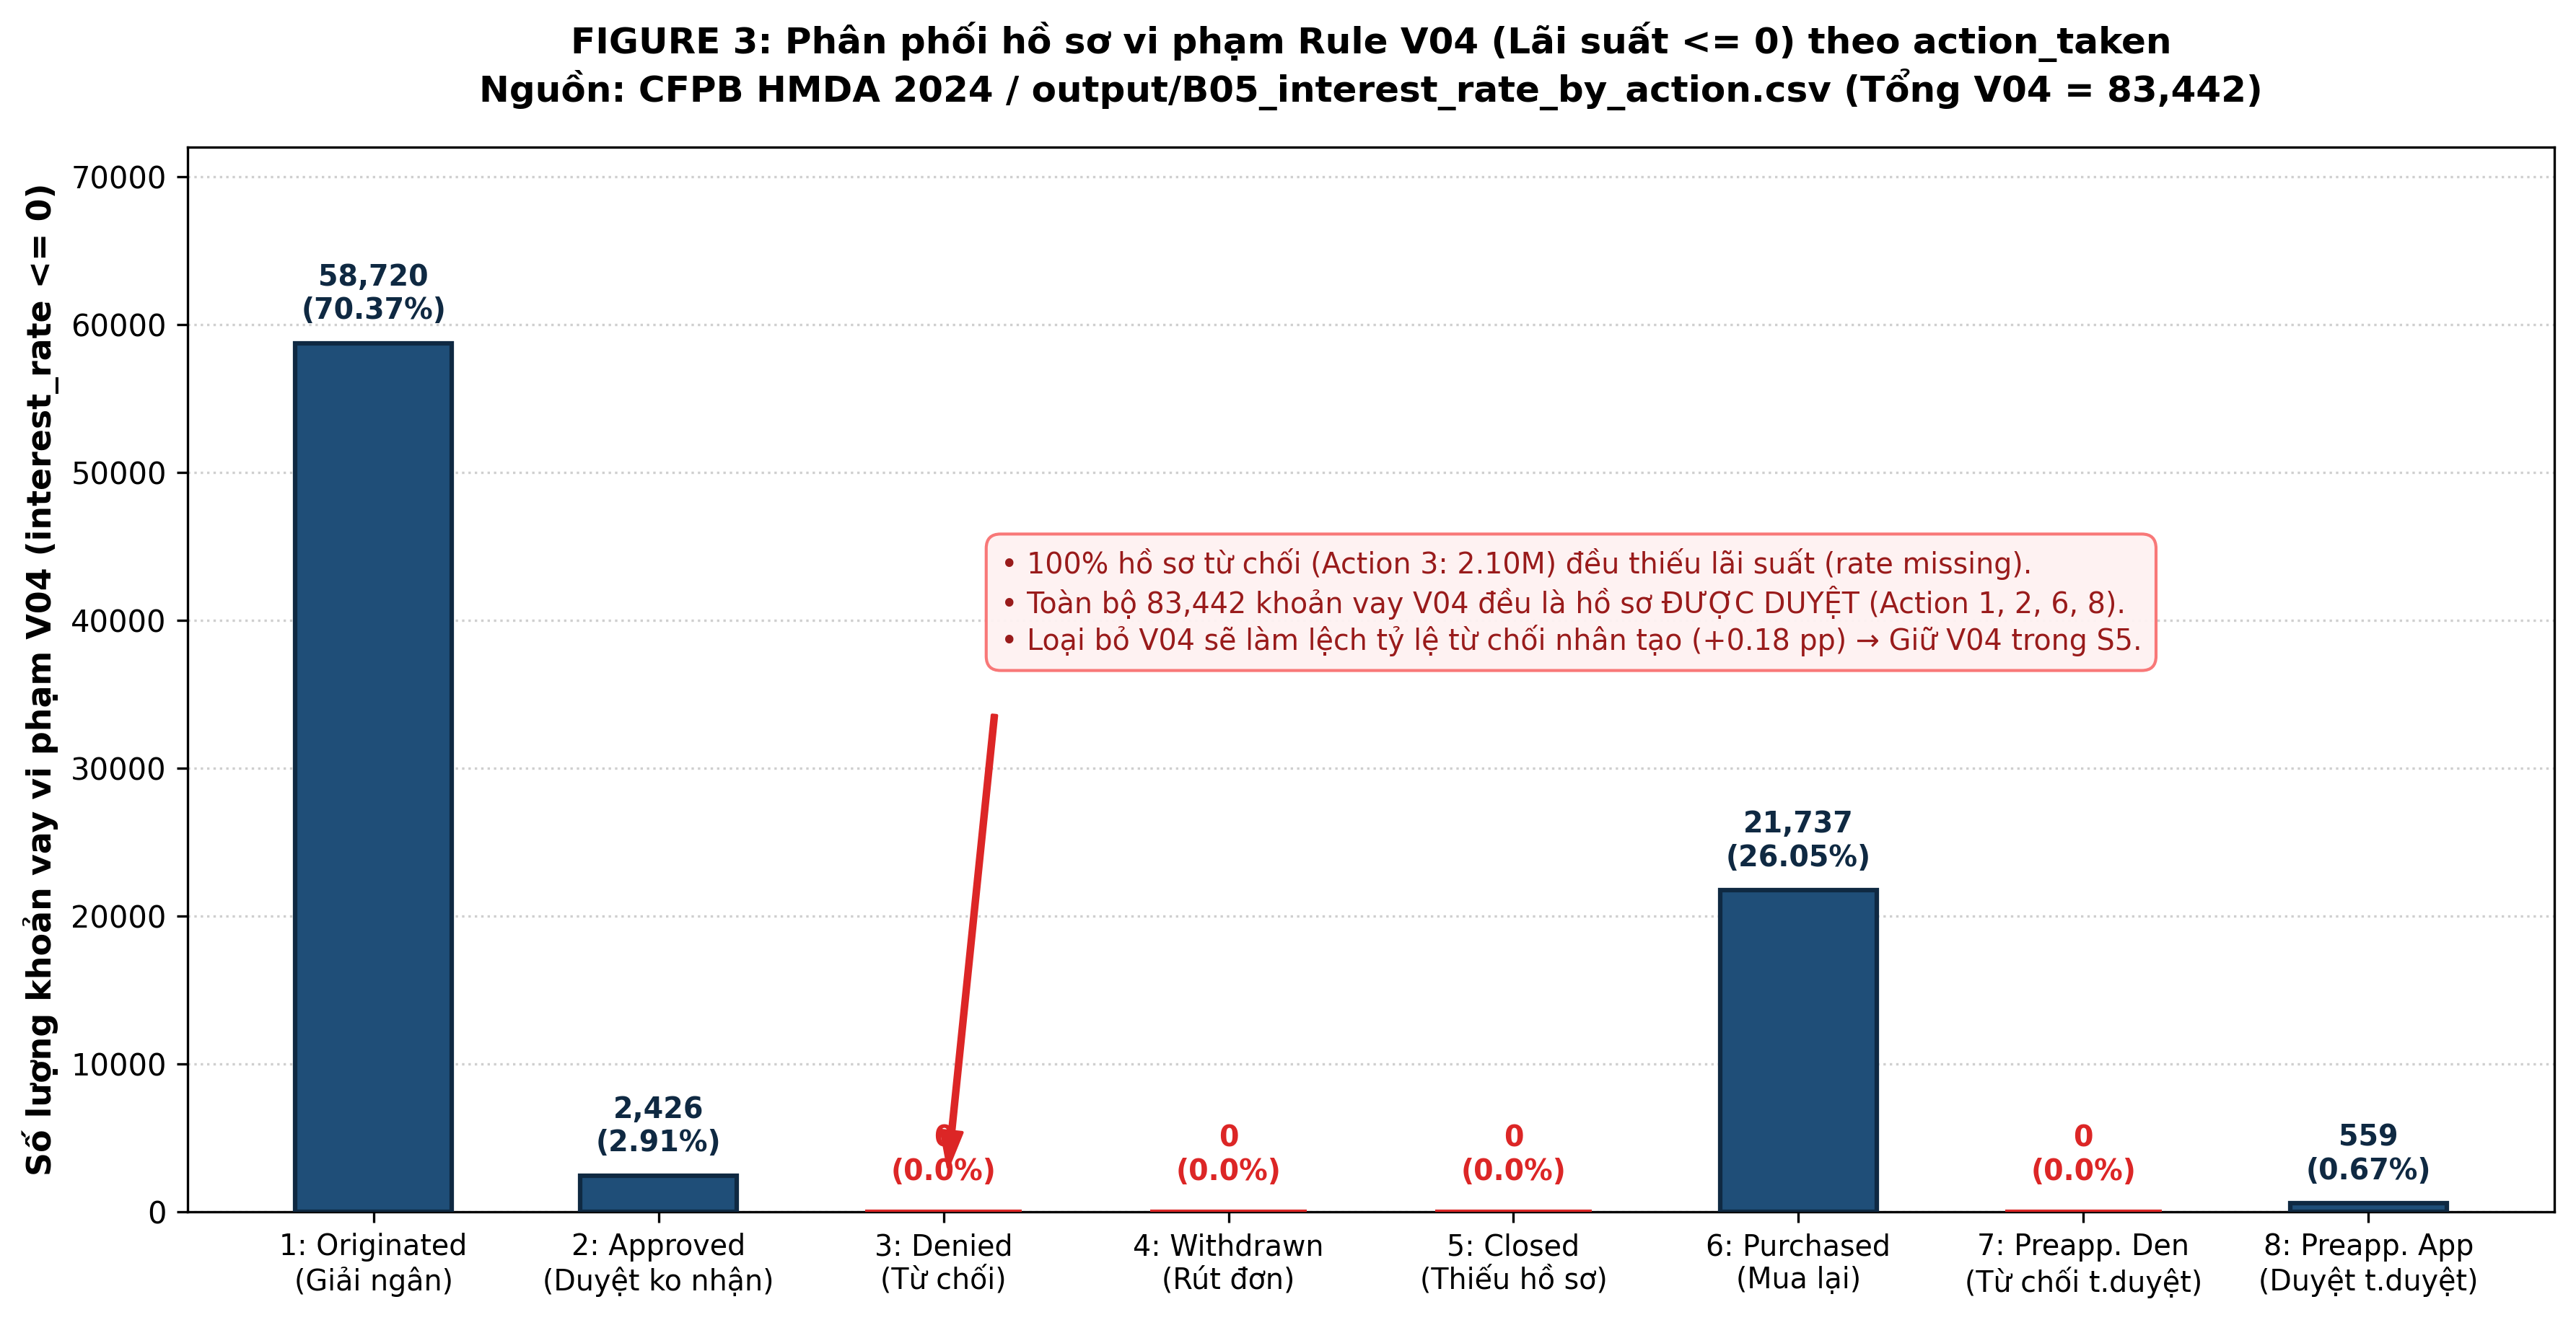

In [74]:
import matplotlib.pyplot as plt

# Step 1: Đọc dữ liệu và định nghĩa nhãn action_taken
df_act = pd.read_csv(OUTPUT_DIR / 'B05_interest_rate_by_action.csv')
labels = ['1: Originated\n(Giải ngân)', '2: Approved\n(Duyệt ko nhận)', '3: Denied\n(Từ chối)', 
          '4: Withdrawn\n(Rút đơn)', '5: Closed\n(Thiếu hồ sơ)', '6: Purchased\n(Mua lại)', 
          '7: Preapp. Den\n(Từ chối t.duyệt)', '8: Preapp. App\n(Duyệt t.duyệt)']
v04_vals = df_act['rate_le0_v04_count'].values
tot_v04 = v04_vals.sum()

# Phối màu: Xanh navy cho hồ sơ có V04 (toàn bộ là duyệt), Đỏ nhạt cảnh báo cho các cột = 0
colors = ['#1f4e78' if c > 0 else '#fee2e2' for c in v04_vals]
edge_colors = ['#0f2942' if c > 0 else '#dc2626' for c in v04_vals]

fig, ax = plt.subplots(figsize=(12, 6.2), dpi=300)
bars = ax.bar(range(8), v04_vals, color=colors, edgecolor=edge_colors, linewidth=1.5, width=0.55, zorder=3)

# Step 2: Gắn nhãn số lượng và % trên đỉnh từng cột
for b, val in zip(bars, v04_vals):
    pct = val * 100.0 / tot_v04 if tot_v04 > 0 else 0
    txt = f'{val:,.0f}\n({pct:.2f}%)' if val > 0 else '0\n(0.0%)'
    txt_col = '#0f2942' if val > 0 else '#dc2626'
    ax.text(b.get_x() + b.get_width()/2., (val if val > 0 else 500) + 1200, txt,
            ha='center', va='bottom', fontsize=9.5, fontweight='bold', color=txt_col)

# Step 3: Hộp chú thích căn cứ kinh tế lượng Decision D-C
ax.annotate('• 100% hồ sơ từ chối (Action 3: 2.10M) đều thiếu lãi suất (rate missing).\n• Toàn bộ 83,442 khoản vay V04 đều là hồ sơ ĐƯỢC DUYỆT (Action 1, 2, 6, 8).\n• Loại bỏ V04 sẽ làm lệch tỷ lệ từ chối nhân tạo (+0.18 pp) → Giữ V04 trong S5.',
            xy=(2, 0), xytext=(2.2, 38000),
            arrowprops=dict(facecolor='#dc2626', edgecolor='#dc2626', width=1.5, headwidth=7, shrink=0.08),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fef2f2', edgecolor='#f87171', alpha=0.95),
            fontsize=9.5, fontweight='medium', color='#991b1b', zorder=5)

ax.set_xticks(range(8)); ax.set_xticklabels(labels, fontsize=9.5, fontweight='medium')
ax.set_ylabel('Số lượng khoản vay vi phạm V04 (interest_rate <= 0)', fontsize=11, fontweight='bold')
ax.set_ylim(0, 72000); ax.grid(axis='y', linestyle=':', alpha=0.6, zorder=0); ax.set_axisbelow(True)
ax.set_title('FIGURE 3: Phân phối hồ sơ vi phạm Rule V04 (Lãi suất <= 0) theo action_taken\nNguồn: CFPB HMDA 2024 / output/B05_interest_rate_by_action.csv (Tổng V04 = 83,442)', fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'B05_figure_3_v04_by_action.png', dpi=300)
plt.show()

## Section 6.2: Step B-2.5 — 4-Column Geographic Identifier Audit (Rules T05, V06) & V07 Engine Divergence Check

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Audit all 4 geographic identifier columns (`state_code`, `county_code`, `census_tract`, `derived_msa_md`) for blank `""`, uppercase `'NA'`, lowercase `'na'`, `'Exempt'`, `'99999'` (candidate non-metropolitan/rural code in `derived_msa_md`), valid format matches, and format violations (Rules T05 & V06).
  - In `derived_msa_md`, assign status `'non_msa'` to code `'99999'` (1,781,406 rows, as of run 2026-10-31, cell 29) [Hypothesis: non-metropolitan indicator; code 99999 is not explicitly defined in the CFPB Data Dictionary].
  - Isolate any non-sentinel `census_tract` rows failing `^[0-9]{11}$` under case-sensitive filtering.
  - Quantify the exact number of rows (57,852 rows, as of run 2026-10-31, cell 29) where **Pandas and PySpark would diverge on Rule V07** if V07 omits an explicit `.notna()` guard on both columns: 55,343 rows have county valid but tract NA; 2,509 rows have county NA but tract valid. After T05 converts sentinel values to `NULL`/`NaN`, PySpark evaluates `county[:5] != tract[:5]` against NULL as `NULL` (`False`), whereas Pandas evaluates `str[:5] != str[:5]` against `NaN` as `True`.
- **Output:** Exported `output/B05_geo_id_audit.csv` and `output/B05_census_tract_anomaly.csv`.

In [60]:
# Step 1: Audit all 4 geographic identifier columns (state_code, county_code, census_tract, derived_msa_md)
geo_specs = [('state_code', '^[A-Z]{2}$'), ('county_code', '^[0-9]{5}$'), ('census_tract', '^[0-9]{11}$'), ('derived_msa_md', '^[0-9]{5}$')]
geo_rows = []
for col, pat in geo_specs:
    q = f"""
    SELECT COUNT(*) FILTER (WHERE TRIM("{col}") = '')::BIGINT AS blank_cnt,
           COUNT(*) FILTER (WHERE TRIM("{col}") = 'NA')::BIGINT AS upper_na_cnt,
           COUNT(*) FILTER (WHERE TRIM("{col}") = 'na')::BIGINT AS lower_na_cnt,
           COUNT(*) FILTER (WHERE UPPER(TRIM("{col}")) = 'EXEMPT')::BIGINT AS exempt_cnt,
           COUNT(*) FILTER (WHERE TRIM("{col}") = '99999')::BIGINT AS code_99999_cnt,
           COUNT(*) FILTER (WHERE UPPER(TRIM("{col}")) NOT IN {SENTINELS_NUM} AND TRIM("{col}") != '99999' AND regexp_matches(TRIM("{col}"), '{pat}'))::BIGINT AS valid_fmt_cnt,
           COUNT(*) FILTER (WHERE UPPER(TRIM("{col}")) NOT IN {SENTINELS_NUM} AND TRIM("{col}") != '99999' AND NOT regexp_matches(TRIM("{col}"), '{pat}'))::BIGINT AS invalid_v06_cnt
    FROM read_parquet('{INPUT_PARQUET.as_posix()}')
    """
    r = duck_conn.execute(q).fetchone()
    assert sum(r) == total_raw_rows
    geo_rows.append({'column_name': col, 'expected_regex': pat, 'blank_cnt': r[0], 'upper_na_cnt': r[1], 'lower_na_cnt': r[2],
                     'exempt_cnt': r[3], 'code_99999_cnt': r[4], 'valid_format_cnt': r[5], 'v06_invalid_format_cnt': r[6]})
geo_summary_df = pd.DataFrame(geo_rows)
save_and_log(geo_summary_df, 'B05_geo_id_audit.csv')

# Step 2: Quantify Pandas vs PySpark NULL-comparison divergence on unguarded V07 and inspect case-sensitive tract anomaly
v07_div_cnt, v07_true_cnt = duck_conn.execute(f"""
SELECT COUNT(*) FILTER (WHERE (UPPER(TRIM(county_code)) IN {SENTINELS_NUM}) != (UPPER(TRIM(census_tract)) IN {SENTINELS_NUM}))::BIGINT,
       COUNT(*) FILTER (WHERE UPPER(TRIM(county_code)) NOT IN {SENTINELS_NUM} AND UPPER(TRIM(census_tract)) NOT IN {SENTINELS_NUM} AND SUBSTRING(TRIM(county_code), 1, 5) != SUBSTRING(TRIM(census_tract), 1, 5))::BIGINT
FROM read_parquet('{INPUT_PARQUET.as_posix()}')
""").fetchone()
print(f"V07 Engine Divergence Check | Unguarded Pandas-vs-Spark NULL divergence rows: {v07_div_cnt:,} | Guarded true mismatches: {v07_true_cnt}")
tract_anomaly_df = duck_conn.execute(f"SELECT row_id, lei, state_code, county_code, census_tract, action_taken FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(census_tract) NOT IN ('', 'NA', 'Exempt') AND NOT regexp_matches(TRIM(census_tract), '^[0-9]{{11}}$')").df()
save_and_log(tract_anomaly_df, 'B05_census_tract_anomaly.csv')
display(geo_summary_df); display(tract_anomaly_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_geo_id_audit.csv | Size: 0.33 KB (335 bytes) | Shape: (4, 9)
V07 Engine Divergence Check | Unguarded Pandas-vs-Spark NULL divergence rows: 57,852 | Guarded true mismatches: 0
Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_census_tract_anomaly.csv | Size: 0.10 KB (102 bytes) | Shape: (1, 6)


,column_name,expected_regex,blank_cnt,upper_na_cnt,lower_na_cnt,exempt_cnt,code_99999_cnt,valid_format_cnt,v06_invalid_format_cnt
0,state_code,^[A-Z]{2}$,0,215946,0,0,0,12043253,0
1,county_code,^[0-9]{5}$,0,296190,0,0,0,11963009,0
2,census_tract,^[0-9]{11}$,0,349023,1,0,0,11910175,0
3,derived_msa_md,^[0-9]{5}$,0,0,0,0,1781406,10477793,0


,row_id,lei,state_code,county_code,census_tract,action_taken
0,1486879,549300Z1CDO1XR2ZMQ19,NA,NA,na,4


## Section 7.1: Step B-2.6 — Extended EDA: `debt_to_income_ratio` Distinct Values & Explicit Bin Set Assertions (Rule T07)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Enumerate every distinct value of `debt_to_income_ratio` across all 12.26M rows with raw application count and dataset percentage.
  - Audit that all values belong to the allowed sets: single-point integers `36` through `49`, ranges (`<20%`, `20-<30%`, `30-<36%`, `50%-60%`, `>60%`), or sentinels (`NA`, `Exempt`, blank).
- **Output:** DTI distinct value profile exported to `output/B05_dti_distinct_profile.csv`.

In [61]:
# Step 1: Enumerate all distinct values of debt_to_income_ratio across 12.26M records
dti_distinct_sql = f"""
SELECT TRIM(debt_to_income_ratio) AS raw_dti_value, COUNT(*)::BIGINT AS raw_count, ROUND(COUNT(*) * 100.0 / {total_raw_rows}, 4) AS raw_share_pct
FROM read_parquet('{INPUT_PARQUET.as_posix()}') GROUP BY 1 ORDER BY raw_count DESC
"""
dti_df = duck_conn.execute(dti_distinct_sql).df()

# Step 2: Verify against allowed sets
allowed_ranges = {'<20%', '20%-<30%', '30%-<36%', '50%-60%', '>60%'}
allowed_points = {str(i) for i in range(36, 50)}
allowed_sentinels = {'', 'NA', 'Exempt', 'EXEMPT'}
all_allowed = allowed_ranges | allowed_points | allowed_sentinels

observed_values = set(dti_df['raw_dti_value'])
unexpected_dti = observed_values - all_allowed
assert len(unexpected_dti) == 0, f"Unexpected DTI values found: {unexpected_dti}"

dti_df['dti_type'] = dti_df['raw_dti_value'].apply(
    lambda v: 'Sentinel' if v in allowed_sentinels else ('Point (Single Integer)' if v in allowed_points else 'Binned Range')
)
save_and_log(dti_df, 'B05_dti_distinct_profile.csv')
display(dti_df.head(10))

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_dti_distinct_profile.csv | Size: 0.84 KB (858 bytes) | Shape: (21, 4)


,raw_dti_value,raw_count,raw_share_pct,dti_type
0,NA,4060236,33.1199,Sentinel
1,30%-<36%,1097751,8.9545,Binned Range
2,20%-<30%,1070929,8.7357,Binned Range
3,50%-60%,825620,6.7347,Binned Range
4,>60%,621916,5.0731,Binned Range
5,<20%,462987,3.7766,Binned Range
6,49,400057,3.2633,Point (Single Integer)
7,44,331700,2.7057,Point (Single Integer)
8,42,315076,2.5701,Point (Single Integer)
9,Exempt,287240,2.3431,Sentinel


## Section 7.2a: Step B-2.6 — Census 7-Field Zero/Negative Partitioning & MSA Zero Audit (Rule T12)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - **Calibrate Rule T12 as strictly per-field:**
    1. **Hidden `0` on `census_tract = 'NA'` rows (6 demographic fields):** All **349,024** tract-NA rows (`96,065` in $S0$, as of run 2026-10-31, cell 33) carry raw `0` in all six tract-level fields (`tract_population`, `tract_minority_population_percent`, `tract_owner_occupied_units`, `tract_one_to_four_family_homes`, `tract_median_age_of_housing_units`, and `tract_to_msa_income_percentage`). Under Decision D-H, these hidden zeros are converted to `NULL` with `<col>_status = 'no_tract'`.
    2. `tract_median_age_of_housing_units`: Only code `-1` (204 rows, as of run 2026-10-31, cell 33) is converted to `NULL` (status `'na_code'`). Value `0` on valid tracts is preserved: 502,156 rows on populated tracts (`pop > 0`) + 220 rows on unpopulated tracts (`pop == 0`) = 502,376 valid-tract zeros [Hypothesis: newly developed tracts; unverified].
    3. `ffiec_msa_md_median_family_income`: Preserved for 55,343 applications with missing census tracts (`census_tract = 'NA'`) but valid county/MSA. Value `0` occurs on exactly 293,681 rows (63,462 in $S0$, as of run 2026-10-31, cell 33), which matches the count where BOTH `county_code` and `census_tract` are missing ($349,024 - 55,343 = 293,681$) and is converted to `NULL` with status `'no_geo'` [Hypothesis: complete absence of geocoding; not an MSA-specific phenomenon, since all 1,471,022 valid-tract rows with code 99999 have 0 zeros in ffiec_income].
    4. `tract_to_msa_income_percentage`: 57,954 zeros exist on valid populated tracts (+220 on zero-pop tracts = 58,174, as of run 2026-10-31, cell 33); preserved as numeric `0` with `flag_tract_income_zero = True`.
- **Output:** Exported `output/B05_tract_domain_audit.csv` and `output/B05_msa_income_zero_crosstab.csv`

In [62]:
# Step 1: Exhaustively partition zeros across 7 Census fields and assert zero_raw == tract_na + pop_zero + pop_pos
tract_num_cols = ['tract_population', 'tract_minority_population_percent', 'ffiec_msa_md_median_family_income',
                  'tract_to_msa_income_percentage', 'tract_owner_occupied_units', 'tract_one_to_four_family_homes', 'tract_median_age_of_housing_units']
t_rows = []
for c in tract_num_cols:
    q = f"""
    WITH base AS (
        SELECT try_cast(TRIM("{c}") AS DOUBLE) AS val, (UPPER(TRIM(census_tract)) IN {SENTINELS_NUM}) AS tract_is_na,
               COALESCE(try_cast(TRIM(tract_population) AS DOUBLE) <= 0, FALSE) AS pop_is_zero,
               (TRIM(derived_msa_md) = '99999') AS msa_is_99999, {S0_SQL_PRED} AS in_s0
        FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE UPPER(TRIM("{c}")) NOT IN {SENTINELS_NUM}
    )
    SELECT MIN(val), MAX(val), COUNT(*) FILTER (WHERE val < 0)::BIGINT, COUNT(*) FILTER (WHERE val = 0)::BIGINT,
           COUNT(*) FILTER (WHERE val = 0 AND tract_is_na)::BIGINT,
           COUNT(*) FILTER (WHERE val = 0 AND NOT tract_is_na AND pop_is_zero)::BIGINT,
           COUNT(*) FILTER (WHERE val = 0 AND NOT tract_is_na AND NOT pop_is_zero)::BIGINT,
           COUNT(*) FILTER (WHERE val = 0 AND msa_is_99999)::BIGINT,
           COUNT(*) FILTER (WHERE in_s0 AND (val < 0 OR (val = 0 AND tract_is_na)))::BIGINT
    FROM base
    """
    r = duck_conn.execute(q).fetchone()
    assert r[3] == r[4] + r[5] + r[6], f"Zero bucket partition mismatch on {c}"
    t_rows.append({'column_name': c, 'min_val': r[0], 'max_val': r[1], 'neg_raw_cnt': r[2], 'zero_raw_cnt': r[3],
                   'zero_tract_na_cnt': r[4], 'zero_pop_zero_cnt': r[5], 'zero_pop_pos_cnt': r[6], 'zero_msa_99999_cnt': r[7], 's0_tract_na_or_neg_cnt': r[8]})
tract_domain_df = pd.DataFrame(t_rows)
save_and_log(tract_domain_df, 'B05_tract_domain_audit.csv')

# Step 2: Cross-tabulate zeros by derived_msa_md = '99999'
msa_zero_df = duck_conn.execute(f"""
SELECT (UPPER(TRIM(census_tract)) IN {SENTINELS_NUM}) AS tract_is_na, (try_cast(TRIM(tract_population) AS DOUBLE) = 0) AS pop_is_zero,
       (TRIM(derived_msa_md) = '99999') AS msa_is_99999, COUNT(*)::BIGINT AS total_rows,
       COUNT(*) FILTER (WHERE try_cast(TRIM(ffiec_msa_md_median_family_income) AS DOUBLE) = 0)::BIGINT AS ffiec_income_zero_cnt,
       COUNT(*) FILTER (WHERE try_cast(TRIM(tract_to_msa_income_percentage) AS DOUBLE) = 0)::BIGINT AS tract_to_msa_pct_zero_cnt
FROM read_parquet('{INPUT_PARQUET.as_posix()}') GROUP BY 1, 2, 3 ORDER BY total_rows DESC
""").df()
save_and_log(msa_zero_df, 'B05_msa_income_zero_crosstab.csv')
display(tract_domain_df); display(msa_zero_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_tract_domain_audit.csv | Size: 0.69 KB (703 bytes) | Shape: (7, 10)
Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_msa_income_zero_crosstab.csv | Size: 0.28 KB (285 bytes) | Shape: (6, 6)


,column_name,min_val,max_val,neg_raw_cnt,zero_raw_cnt,zero_tract_na_cnt,zero_pop_zero_cnt,zero_pop_pos_cnt,zero_msa_99999_cnt,s0_tract_na_or_neg_cnt
0,tract_population,0.0,37892.0,0,349244,349024,220,0,310384,96065
1,tract_minority_population_percent,0.0,100.0,0,349456,349024,220,212,310588,96065
2,ffiec_msa_md_median_family_income,0.0,201300.0,0,293681,293681,0,0,293681,63462
3,tract_to_msa_income_percentage,0.0,516.0,0,407198,349024,220,57954,314745,96065
4,tract_owner_occupied_units,0.0,6276.0,0,352239,349024,220,2995,310421,96065
5,tract_one_to_four_family_homes,0.0,8233.0,0,352604,349024,219,3361,310598,96065
6,tract_median_age_of_housing_units,-1.0,80.0,204,851400,349024,220,502156,339726,96225


,tract_is_na,pop_is_zero,msa_is_99999,total_rows,ffiec_income_zero_cnt,tract_to_msa_pct_zero_cnt
0,False,False,False,10438933,0,53593
1,False,False,True,1471022,0,4361
2,True,True,True,310376,293681,310376
3,True,True,False,38648,0,38648
4,False,True,False,212,0,212
5,False,True,True,8,0,8


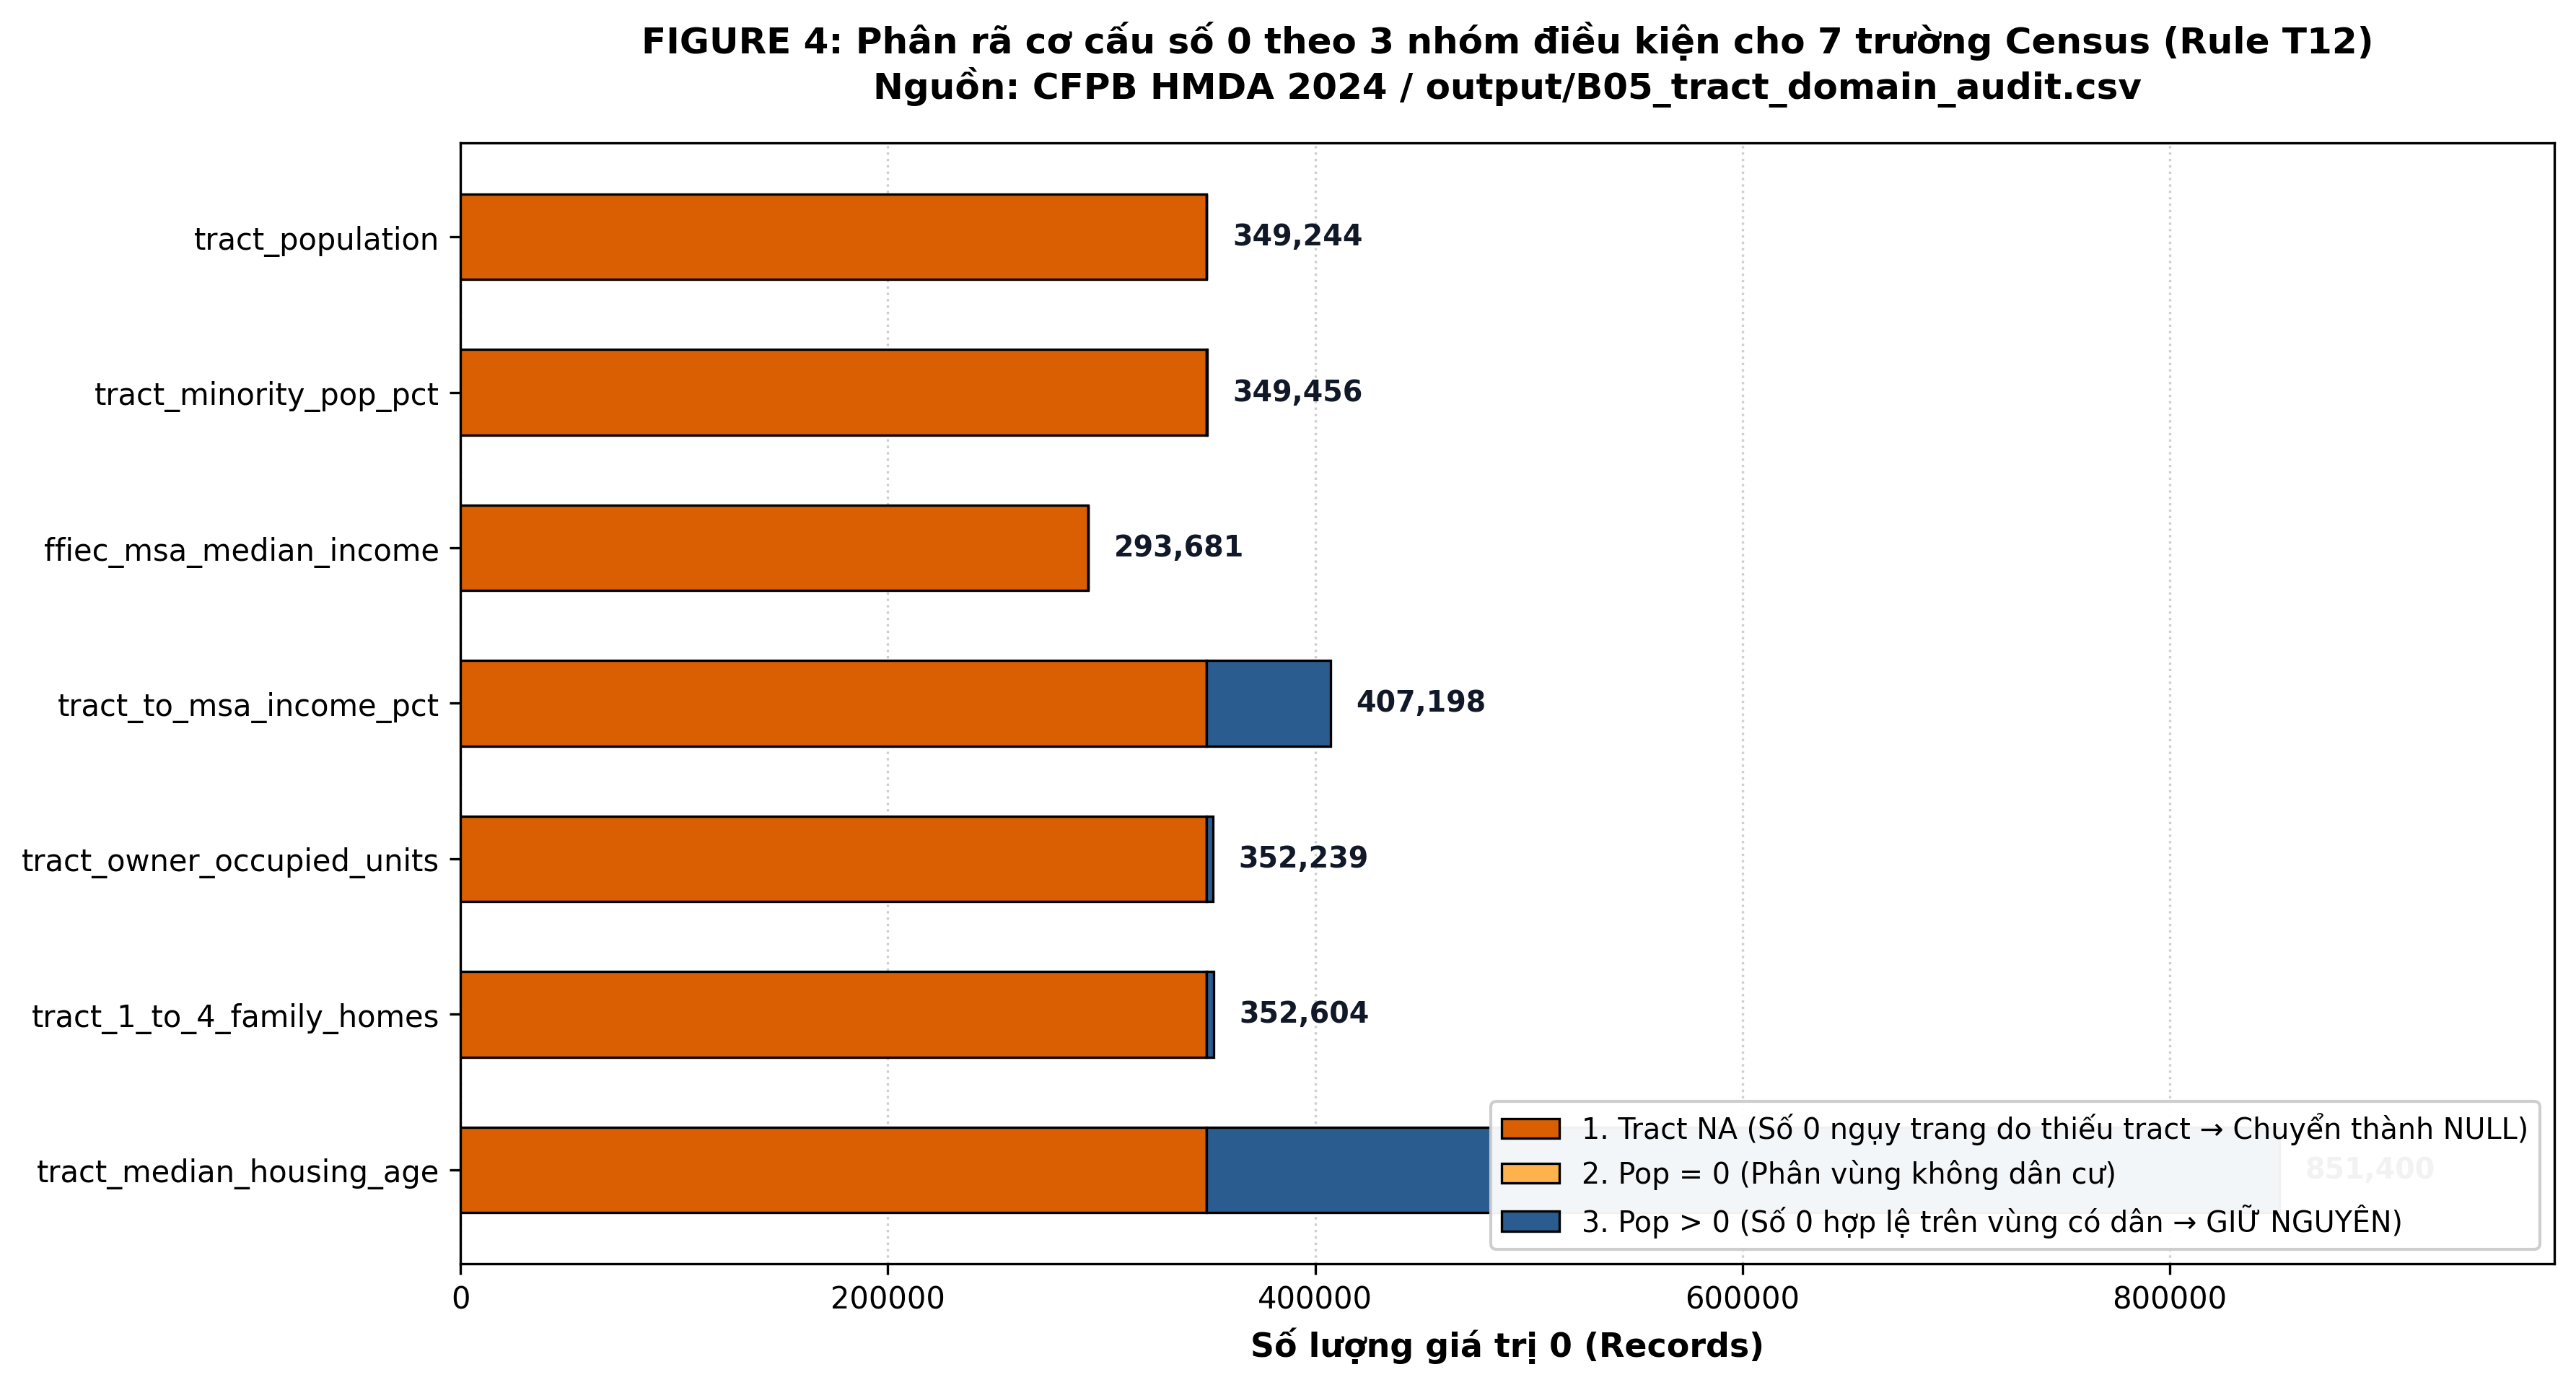

In [75]:
import matplotlib.pyplot as plt

# Step 1: Đọc dữ liệu audit 7 trường Census
df_tract = pd.read_csv(OUTPUT_DIR / 'B05_tract_domain_audit.csv')
name_map = {
    'tract_population': 'tract_population', 'tract_minority_population_percent': 'tract_minority_pop_pct',
    'ffiec_msa_md_median_family_income': 'ffiec_msa_median_income', 'tract_to_msa_income_percentage': 'tract_to_msa_income_pct',
    'tract_owner_occupied_units': 'tract_owner_occupied_units', 'tract_one_to_four_family_homes': 'tract_1_to_4_family_homes',
    'tract_median_age_of_housing_units': 'tract_median_housing_age'
}
labels = df_tract['column_name'].map(name_map)
y_pos = range(len(df_tract))
c1, c2, c3 = df_tract['zero_tract_na_cnt'].values, df_tract['zero_pop_zero_cnt'].values, df_tract['zero_pop_pos_cnt'].values

fig, ax = plt.subplots(figsize=(12, 6.5), dpi=300)

# Step 2: Vẽ 3 lớp cột chồng (Tract NA -> Pop=0 -> Pop>0)
ax.barh(y_pos, c1, color='#d95f02', edgecolor='black', linewidth=0.8, height=0.55, label='1. Tract NA (Số 0 ngụy trang do thiếu tract → Chuyển thành NULL)', zorder=3)
ax.barh(y_pos, c2, left=c1, color='#feb24c', edgecolor='black', linewidth=0.8, height=0.55, label='2. Pop = 0 (Phân vùng không dân cư)', zorder=3)
ax.barh(y_pos, c3, left=c1 + c2, color='#2b5c8f', edgecolor='black', linewidth=0.8, height=0.55, label='3. Pop > 0 (Số 0 hợp lệ trên vùng có dân → GIỮ NGUYÊN)', zorder=3)

# Step 3: Gắn tổng số lượng 0 ở cuối mỗi thanh
for i, tot in enumerate(df_tract['zero_raw_cnt']):
    ax.text(tot + 12000, i, f'{tot:,.0f}', va='center', ha='left', fontsize=9.5, fontweight='bold', color='#111827')

ax.set_yticks(y_pos); ax.set_yticklabels(labels, fontsize=10, fontweight='medium'); ax.invert_yaxis()
ax.set_xlabel('Số lượng giá trị 0 (Records)', fontsize=11, fontweight='bold')
ax.set_xlim(0, 980000); ax.grid(axis='x', linestyle=':', alpha=0.6, zorder=0); ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=True, fontsize=9.5, framealpha=0.95)
ax.set_title('FIGURE 4: Phân rã cơ cấu số 0 theo 3 nhóm điều kiện cho 7 trường Census (Rule T12)\nNguồn: CFPB HMDA 2024 / output/B05_tract_domain_audit.csv', fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'B05_figure_4_tract_zeros_stacked.png', dpi=300)
plt.show()

## Section 7.2b: Step B-2.6 — Pre-RQ3 Missing Census Tract Disparity Audit across Racial Groups

- **Input:** `B04_raw_with_buckets.parquet` restricted to Analytic Baseline $S0$.
- **Process:**
  - Audit the 96,065 Analytic Sample $S0$ applications lacking a census tract (`census_tract = 'NA'`).
  - Cross-tabulate application count, share of applications missing tracts, and denial rates by `derived_race`.
  - Include an explicit `All S0 (Overall)` summary row in the query so that the overall 96,065 rows and 76.53% denial rate are directly computed and traceable per Rule 4.3.
- **Output:** Exported `output/B05_tract_na_rq3_crosstab.csv`.

In [63]:
# Step 1: Pre-RQ3 Missing Census Tract Disparity Audit across Racial Groups in S0 (with Overall Row)
tract_rq3_sql = f"""
WITH base AS (
    SELECT derived_race, (UPPER(TRIM(census_tract)) IN {SENTINELS_NUM}) AS tract_is_na, TRIM(action_taken) = '3' AS is_denied
    FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE {S0_SQL_PRED}
),
by_race AS (
    SELECT derived_race, COUNT(*) FILTER (WHERE NOT tract_is_na)::BIGINT AS valid_tract_apps,
           ROUND(AVG(CASE WHEN NOT tract_is_na AND is_denied THEN 1.0 WHEN NOT tract_is_na THEN 0.0 END) * 100, 2) AS valid_tract_denial_rate_pct,
           COUNT(*) FILTER (WHERE tract_is_na)::BIGINT AS na_tract_apps,
           ROUND(AVG(CASE WHEN tract_is_na AND is_denied THEN 1.0 WHEN tract_is_na THEN 0.0 END) * 100, 2) AS na_tract_denial_rate_pct,
           ROUND(COUNT(*) FILTER (WHERE tract_is_na) * 100.0 / COUNT(*), 2) AS na_tract_share_pct
    FROM base GROUP BY derived_race
),
overall AS (
    SELECT 'All S0 (Overall)' AS derived_race, COUNT(*) FILTER (WHERE NOT tract_is_na)::BIGINT AS valid_tract_apps,
           ROUND(AVG(CASE WHEN NOT tract_is_na AND is_denied THEN 1.0 WHEN NOT tract_is_na THEN 0.0 END) * 100, 2) AS valid_tract_denial_rate_pct,
           COUNT(*) FILTER (WHERE tract_is_na)::BIGINT AS na_tract_apps,
           ROUND(AVG(CASE WHEN tract_is_na AND is_denied THEN 1.0 WHEN tract_is_na THEN 0.0 END) * 100, 2) AS na_tract_denial_rate_pct,
           ROUND(COUNT(*) FILTER (WHERE tract_is_na) * 100.0 / COUNT(*), 2) AS na_tract_share_pct
    FROM base
)
SELECT * FROM overall UNION ALL (SELECT * FROM by_race ORDER BY (valid_tract_apps + na_tract_apps) DESC)
"""
tract_rq3_df = duck_conn.execute(tract_rq3_sql).df()
save_and_log(tract_rq3_df, 'B05_tract_na_rq3_crosstab.csv')
display(tract_rq3_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_tract_na_rq3_crosstab.csv | Size: 0.59 KB (608 bytes) | Shape: (10, 6)


,derived_race,valid_tract_apps,valid_tract_denial_rate_pct,na_tract_apps,na_tract_denial_rate_pct,na_tract_share_pct
0,All S0 (Overall),8040599,24.00,96065,76.53,1.18
1,White,5301793,21.34,58831,73.91,1.10
2,Race Not Available,1259799,29.09,15441,75.86,1.21
3,Black or African American,717399,35.69,15704,87.14,2.14
4,Asian,476965,21.66,1532,56.01,0.32
5,Joint,182404,18.90,2132,77.91,1.16
6,American Indian or Alaska Native,59660,35.68,1737,86.47,2.83
7,2 or more minority races,20631,37.43,289,91.70,1.38
8,Native Hawaiian or Other Pacific Islander,19870,37.90,379,90.50,1.87
9,Free Form Text Only,2078,58.18,20,75.00,0.95


## Section 7.3a: Step B-2.6 — Signed CLTV Difference & Rounding Bounds by Lien Status (Rules V09 & X07)

- **Input:** `B04_raw_with_buckets.parquet` restricted to Analytic Baseline $S0$ with valid positive CLTV, loan amount, and property value.
- **Process:**
  - **Empirical Diagnostic Profile (V09):** In public HMDA, reported CLTV and calculated LTV ($\text{loan\_amount} / \text{property\_value} \times 100$) diverge systematically.
  - Property value ($P_{\text{mid}}$) is rounded to the midpoint of the nearest $\$10,000$ interval ($[P_{\text{mid}} - 5000, P_{\text{mid}} + 5000]$).
  - The theoretical lower rounding bound under property rounding is:
    $$\text{ltv\_min\_bound} = \frac{\text{loan\_amount}}{\text{property\_value} + 5000} \times 100$$
  - Profile the distribution of signed differences and rounding bounds by `lien_status`.
- **Output:** Exported `output/B05_v09_cltv_discrepancy_profile.csv`.

In [64]:
# Step 1: Evaluate signed (cltv - ltv_calc) and rounding-bounded differences in S0 by lien_status
cltv_diff_sql = f"""
WITH valid_s0 AS (
    SELECT
        TRIM(lien_status) AS lien_status, try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) AS cltv,
        (try_cast(TRIM(loan_amount) AS DOUBLE) / try_cast(TRIM(property_value) AS DOUBLE)) * 100.0 AS ltv_calc,
        (try_cast(TRIM(loan_amount) AS DOUBLE) / (try_cast(TRIM(property_value) AS DOUBLE) + 5000.0)) * 100.0 AS ltv_min_bound,
        (try_cast(TRIM(loan_amount) AS DOUBLE) / GREATEST(try_cast(TRIM(property_value) AS DOUBLE) - 5000.0, 1000.0)) * 100.0 AS ltv_max_bound
    FROM read_parquet('{INPUT_PARQUET.as_posix()}')
    WHERE {S0_SQL_PRED} AND UPPER(TRIM(combined_loan_to_value_ratio)) NOT IN {SENTINELS_NUM}
      AND UPPER(TRIM(property_value)) NOT IN {SENTINELS_NUM}
      AND try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) > 0
      AND try_cast(TRIM(property_value) AS DOUBLE) > 0 AND try_cast(TRIM(loan_amount) AS DOUBLE) > 0
)
SELECT
    lien_status, CASE WHEN lien_status = '1' THEN '1 - First Lien' WHEN lien_status = '2' THEN '2 - Subordinate Lien' ELSE lien_status END AS lien_label,
    COUNT(*)::BIGINT AS valid_s0_apps, ROUND(quantile_cont(ABS(cltv - ltv_calc), 0.50), 3) AS p50_abs_diff_pp, ROUND(quantile_cont(ABS(cltv - ltv_calc), 0.95), 3) AS p95_abs_diff_pp,
    COUNT(*) FILTER (WHERE cltv >= ltv_min_bound - 0.05 AND cltv <= ltv_max_bound + 0.05)::BIGINT AS within_10k_rounding_bounds_cnt,
    ROUND(COUNT(*) FILTER (WHERE cltv >= ltv_min_bound - 0.05 AND cltv <= ltv_max_bound + 0.05) * 100.0 / COUNT(*), 2) AS within_10k_rounding_pct,
    COUNT(*) FILTER (WHERE cltv < ltv_min_bound - 1.0)::BIGINT AS cltv_below_ltv_min_1pp_cnt,
    ROUND(COUNT(*) FILTER (WHERE cltv < ltv_min_bound - 1.0) * 100.0 / COUNT(*), 2) AS cltv_below_ltv_min_1pp_pct,
    COUNT(*) FILTER (WHERE cltv < ltv_min_bound - 5.0)::BIGINT AS cltv_below_ltv_min_5pp_cnt,
    COUNT(*) FILTER (WHERE cltv > ltv_max_bound + 10.0)::BIGINT AS cltv_above_ltv_max_10pp_cnt
FROM valid_s0 GROUP BY lien_status ORDER BY lien_status
"""
cltv_diff_df = duck_conn.execute(cltv_diff_sql).df()
save_and_log(cltv_diff_df, 'B05_v09_cltv_discrepancy_profile.csv')
display(cltv_diff_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_v09_cltv_discrepancy_profile.csv | Size: 0.38 KB (387 bytes) | Shape: (2, 11)


,lien_status,lien_label,valid_s0_apps,p50_abs_diff_pp,p95_abs_diff_pp,within_10k_rounding_bounds_cnt,within_10k_rounding_pct,cltv_below_ltv_min_1pp_cnt,cltv_below_ltv_min_1pp_pct,cltv_below_ltv_min_5pp_cnt,cltv_above_ltv_max_10pp_cnt
0,1,1 - First Lien,5033106,0.755,4.710,2970828,59.03,442881,8.8,19301,65857
1,2,2 - Subordinate Lien,2194823,49.276,89.766,17731,0.81,13223,0.6,832,2084556


## Section 7.3b: Step B-2.6 — First-Lien Rounding Bounds by Loan Type (Financed Fees Hypothesis)

- **Input:** `B04_raw_with_buckets.parquet` restricted to Analytic Baseline $S0$ first liens (`lien_status == '1'`).
- **Process:**
  - Test the hypothesis that institutional fee structures explain why first-lien loans fall below rounding bounds:
    Under FHA (Loan Type 2) and VA (Loan Type 3), borrowers finance upfront mortgage insurance premiums (FHA UFMIP: 1.75%) or VA funding fees (1.25%–3.3%) directly into the promissory note (`loan_amount`), which inflates `loan_amount` relative to reported CLTV [Hypothesis: candidate cause].
  - Note: In HMDA Data Dictionary, `property_value` is documented as midpoint-rounded to $\$10,000$, whereas `loan_amount` is documented only as integer values [Hypothesis: candidate rounding].
  - Cross-tabulate first-lien loans falling below `ltv_min_bound - 1pp` by `loan_type` (Conventional vs. FHA vs. VA vs. USDA).
- **Output:** Exported `output/B05_v09_cltv_by_loantype.csv`.

In [65]:
# Step 1: Cross-tabulate first-lien CLTV rounding bounds by loan_type to test financed fees hypothesis
cltv_lt_sql = f"""
WITH valid_first_lien AS (
    SELECT
        TRIM(loan_type) AS loan_type, try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) AS cltv,
        (try_cast(TRIM(loan_amount) AS DOUBLE) / try_cast(TRIM(property_value) AS DOUBLE)) * 100.0 AS ltv_calc,
        (try_cast(TRIM(loan_amount) AS DOUBLE) / (try_cast(TRIM(property_value) AS DOUBLE) + 5000.0)) * 100.0 AS ltv_min_bound,
        (try_cast(TRIM(loan_amount) AS DOUBLE) / GREATEST(try_cast(TRIM(property_value) AS DOUBLE) - 5000.0, 1000.0)) * 100.0 AS ltv_max_bound
    FROM read_parquet('{INPUT_PARQUET.as_posix()}')
    WHERE {S0_SQL_PRED} AND TRIM(lien_status) = '1' AND UPPER(TRIM(combined_loan_to_value_ratio)) NOT IN {SENTINELS_NUM}
      AND UPPER(TRIM(property_value)) NOT IN {SENTINELS_NUM} AND try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) > 0
      AND try_cast(TRIM(property_value) AS DOUBLE) > 0 AND try_cast(TRIM(loan_amount) AS DOUBLE) > 0
)
SELECT
    loan_type, CASE WHEN loan_type = '1' THEN '1 - Conventional' WHEN loan_type = '2' THEN '2 - FHA' WHEN loan_type = '3' THEN '3 - VA' WHEN loan_type = '4' THEN '4 - USDA/RHS' ELSE loan_type END AS loan_type_label,
    COUNT(*)::BIGINT AS total_first_lien_apps,
    COUNT(*) FILTER (WHERE cltv >= ltv_min_bound - 0.05 AND cltv <= ltv_max_bound + 0.05)::BIGINT AS within_rounding_cnt,
    ROUND(COUNT(*) FILTER (WHERE cltv >= ltv_min_bound - 0.05 AND cltv <= ltv_max_bound + 0.05) * 100.0 / COUNT(*), 2) AS within_rounding_pct,
    COUNT(*) FILTER (WHERE cltv < ltv_min_bound - 1.0)::BIGINT AS below_min_1pp_cnt,
    ROUND(COUNT(*) FILTER (WHERE cltv < ltv_min_bound - 1.0) * 100.0 / COUNT(*), 2) AS below_min_1pp_pct,
    COUNT(*) FILTER (WHERE cltv > ltv_max_bound + 1.0)::BIGINT AS above_max_1pp_cnt,
    ROUND(COUNT(*) FILTER (WHERE cltv > ltv_max_bound + 1.0) * 100.0 / COUNT(*), 2) AS above_max_1pp_pct
FROM valid_first_lien GROUP BY 1, 2 ORDER BY 1
"""
cltv_lt_df = duck_conn.execute(cltv_lt_sql).df()
save_and_log(cltv_lt_df, 'B05_v09_cltv_by_loantype.csv')
display(cltv_lt_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_v09_cltv_by_loantype.csv | Size: 0.38 KB (389 bytes) | Shape: (4, 9)


,loan_type,loan_type_label,total_first_lien_apps,within_rounding_cnt,within_rounding_pct,below_min_1pp_cnt,below_min_1pp_pct,above_max_1pp_cnt,above_max_1pp_pct
0,1,1 - Conventional,3496495,2138833,61.17,165820,4.74,219663,6.28
1,2,2 - FHA,1030900,491808,47.71,203583,19.75,90717,8.80
2,3,3 - VA,468830,312921,66.75,70192,14.97,15680,3.34
3,4,4 - USDA/RHS,36881,27266,73.93,3286,8.91,2985,8.09


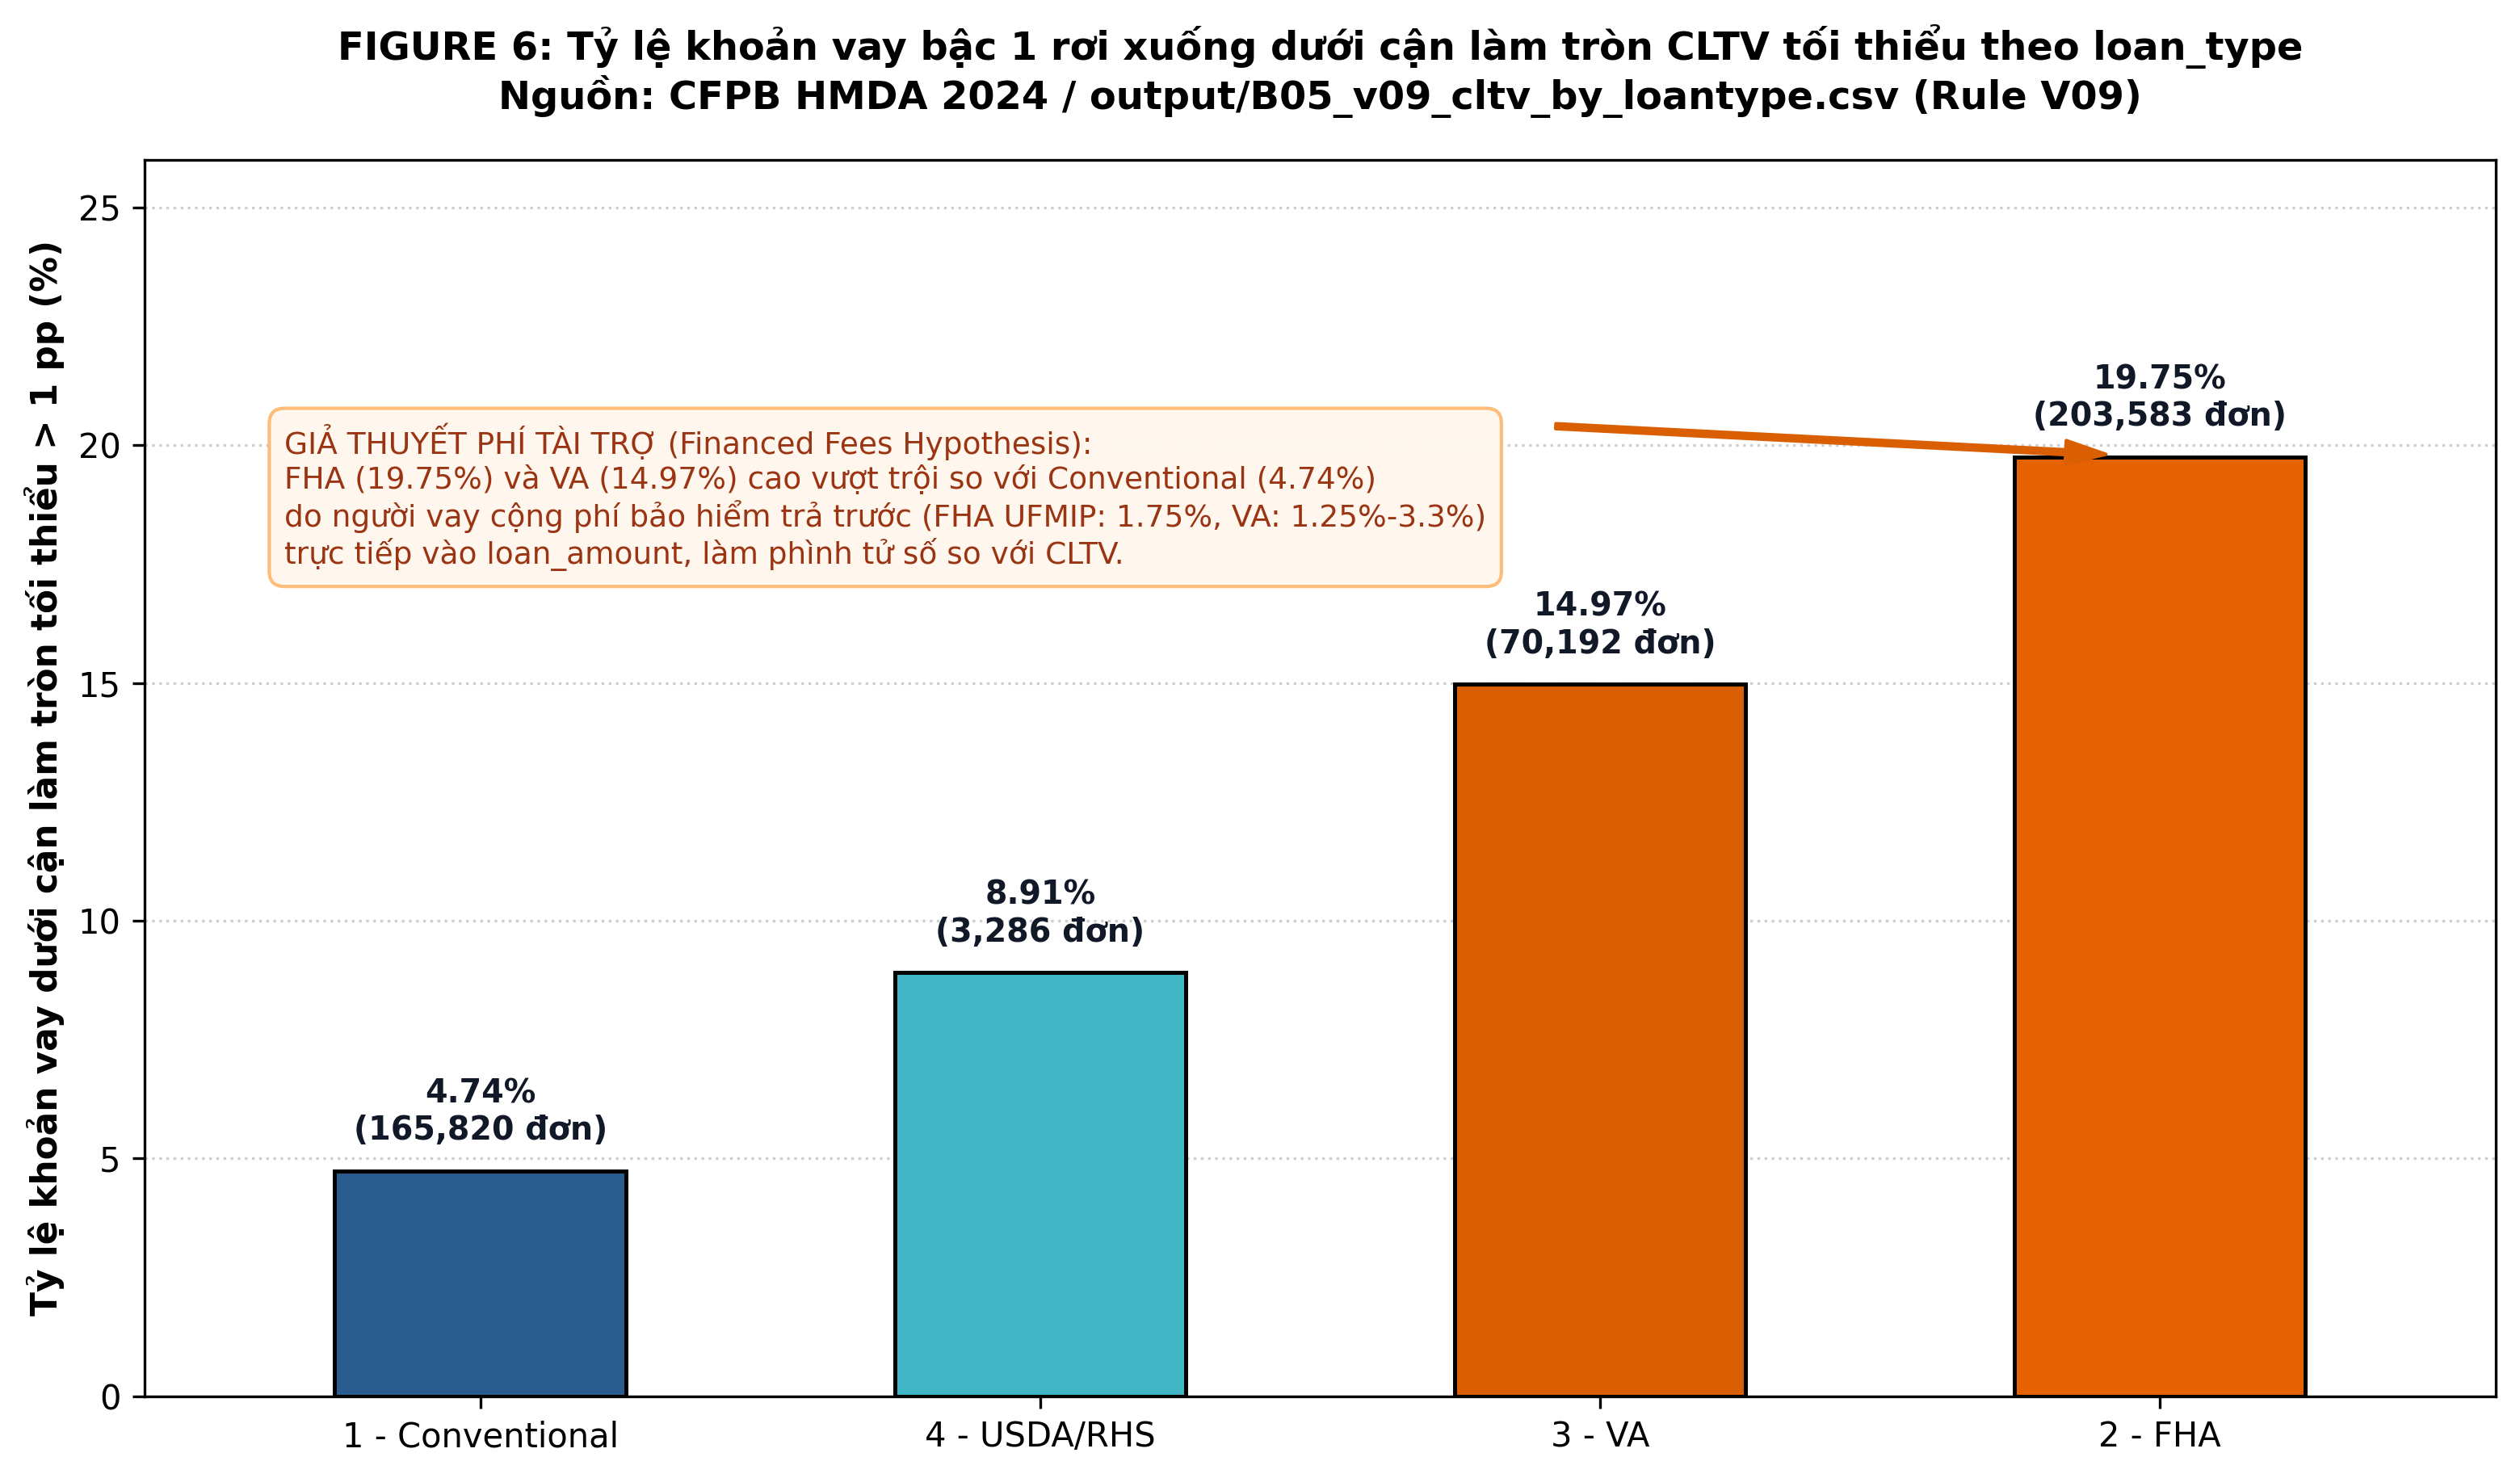

In [78]:
import matplotlib.pyplot as plt

# Step 1: Đọc dữ liệu và sắp xếp tăng dần theo tỷ lệ dưới cận
df_lt = pd.read_csv(OUTPUT_DIR / 'B05_v09_cltv_by_loantype.csv')
df_s = df_lt.sort_values(by='below_min_1pp_pct').reset_index(drop=True)

labels = df_s['loan_type_label'].values
pcts = df_s['below_min_1pp_pct'].values
counts = df_s['below_min_1pp_cnt'].values

# Phối màu: Xanh dương cho Conventional; Cam/Đỏ nổi bật cho FHA và VA
colors = ['#2b5c8f' if 'Conventional' in l else ('#e66101' if 'FHA' in l else ('#d95f02' if 'VA' in l else '#41b6c4')) for l in labels]

fig, ax = plt.subplots(figsize=(10.5, 6.2), dpi=300)
bars = ax.bar(range(4), pcts, color=colors, edgecolor='black', linewidth=1.2, width=0.52, zorder=3)

# Step 2: Gắn nhãn tỷ lệ % và số đơn vị trên đỉnh cột
for b, p, c in zip(bars, pcts, counts):
    ax.text(b.get_x() + b.get_width()/2., p + 0.5, f'{p:.2f}%\n({c:,.0f} đơn)',
            ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#111827')

# Step 3: Hộp chú thích đã dời sang góc trên bên trái, KHÔNG che cột VA (x=2)
ax.annotate('GIẢ THUYẾT PHÍ TÀI TRỢ (Financed Fees Hypothesis):\nFHA (19.75%) và VA (14.97%) cao vượt trội so với Conventional (4.74%)\ndo người vay cộng phí bảo hiểm trả trước (FHA UFMIP: 1.75%, VA: 1.25%-3.3%)\ntrực tiếp vào loan_amount, làm phình tử số so với CLTV.',
            xy=(3, 19.75), xytext=(-0.35, 17.5),
            arrowprops=dict(facecolor='#d95f02', edgecolor='#d95f02', width=1.5, headwidth=7, shrink=0.08),
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff7ed', edgecolor='#fdba74', alpha=0.95),
            fontsize=9, fontweight='medium', color='#9a3412', zorder=5)

ax.set_xticks(range(4)); ax.set_xticklabels(labels, fontsize=10, fontweight='medium')
ax.set_ylabel('Tỷ lệ khoản vay dưới cận làm tròn tối thiểu > 1 pp (%)', fontsize=10.5, fontweight='bold')
ax.set_ylim(0, 26); ax.set_xlim(-0.6, 3.6)
ax.grid(axis='y', linestyle=':', alpha=0.6, zorder=0); ax.set_axisbelow(True)
ax.set_title('FIGURE 6: Tỷ lệ khoản vay bậc 1 rơi xuống dưới cận làm tròn CLTV tối thiểu theo loan_type\nNguồn: CFPB HMDA 2024 / output/B05_v09_cltv_by_loantype.csv (Rule V09)', fontsize=11.5, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'B05_figure_6_cltv_by_loantype.png', dpi=300)
plt.show()

## Section 7.4a: Step B-2.6 — Extended EDA: Racial Selection Waterfall Across F01, S0, and `fin_complete` (Rule X11)

- **Input:** `B04_raw_with_buckets.parquet`.
- **Process:**
  - Track application counts, retention rates, and denial rates across all 9 `derived_race` groups from **F01** (`action_taken IN ('1','2','3')`) $\rightarrow$ **Analytic Sample $S0$** $\rightarrow$ **`fin_complete = True`** (non-sentinel DTI, CLTV, Income, and Loan Amount).
- **Output:** Racial selection waterfall exported to `output/B05_x11_race_selection_waterfall.csv`.

In [66]:
# Step 1: Query racial composition and denial rates across F01, Analytic S0, and fin_complete (X11)
race_wf_sql = f"""
WITH flags AS (
    SELECT derived_race, TRIM(action_taken) AS action_taken, (TRIM(action_taken) IN ('1', '2', '3')) AS in_f01, {S0_SQL_PRED} AS in_s0,
        (UPPER(TRIM(debt_to_income_ratio)) NOT IN {SENTINELS_NUM} AND UPPER(TRIM(combined_loan_to_value_ratio)) NOT IN {SENTINELS_NUM}
         AND UPPER(TRIM(income)) NOT IN {SENTINELS_NUM} AND UPPER(TRIM(loan_amount)) NOT IN {SENTINELS_NUM}) AS fin_ok
    FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE TRIM(action_taken) IN ('1', '2', '3')
)
SELECT
    derived_race,
    COUNT(*) FILTER (WHERE in_f01)::BIGINT AS f01_apps,
    ROUND(COUNT(*) FILTER (WHERE in_f01 AND action_taken = '3') * 100.0 / COUNT(*) FILTER (WHERE in_f01), 2) AS f01_denial_rate_pct,
    COUNT(*) FILTER (WHERE in_s0)::BIGINT AS s0_apps,
    ROUND(COUNT(*) FILTER (WHERE in_s0 AND action_taken = '3') * 100.0 / COUNT(*) FILTER (WHERE in_s0), 2) AS s0_denial_rate_pct,
    COUNT(*) FILTER (WHERE in_s0 AND fin_ok)::BIGINT AS fin_complete_apps,
    ROUND(COUNT(*) FILTER (WHERE in_s0 AND fin_ok) * 100.0 / COUNT(*) FILTER (WHERE in_s0), 2) AS fin_retained_of_s0_pct,
    ROUND(COUNT(*) FILTER (WHERE in_s0 AND fin_ok AND action_taken = '3') * 100.0 / COUNT(*) FILTER (WHERE in_s0 AND fin_ok), 2) AS fin_denial_rate_pct
FROM flags GROUP BY derived_race ORDER BY s0_apps DESC
"""
race_wf_df = duck_conn.execute(race_wf_sql).df()
race_wf_df['denial_shift_s0_to_fin_pp'] = (race_wf_df['fin_denial_rate_pct'] - race_wf_df['s0_denial_rate_pct']).round(2)
assert race_wf_df['s0_apps'].sum() == tot_analytic
save_and_log(race_wf_df, 'B05_x11_race_selection_waterfall.csv')
display(race_wf_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_x11_race_selection_waterfall.csv | Size: 0.78 KB (795 bytes) | Shape: (9, 9)


,derived_race,f01_apps,f01_denial_rate_pct,s0_apps,s0_denial_rate_pct,fin_complete_apps,fin_retained_of_s0_pct,fin_denial_rate_pct,denial_shift_s0_to_fin_pp
0,White,5550877,21.81,5360624,21.92,4699459,87.67,19.63,-2.29
1,Race Not Available,1526078,27.76,1275240,29.66,1027404,80.57,25.87,-3.79
2,Black or African American,762461,36.66,733103,36.80,615372,83.94,33.40,-3.40
3,Asian,524984,21.27,478497,21.77,446231,93.26,20.68,-1.09
4,Joint,189064,19.54,184536,19.58,162116,87.85,17.07,-2.51
5,American Indian or Alaska Native,63158,37.03,61397,37.11,49896,81.27,32.82,-4.29
6,2 or more minority races,21855,38.03,20920,38.18,17556,83.92,34.77,-3.41
7,Native Hawaiian or Other Pacific Islander,21118,38.70,20249,38.89,17351,85.69,36.36,-2.53
8,Free Form Text Only,2184,58.97,2098,58.34,1978,94.28,57.13,-1.21


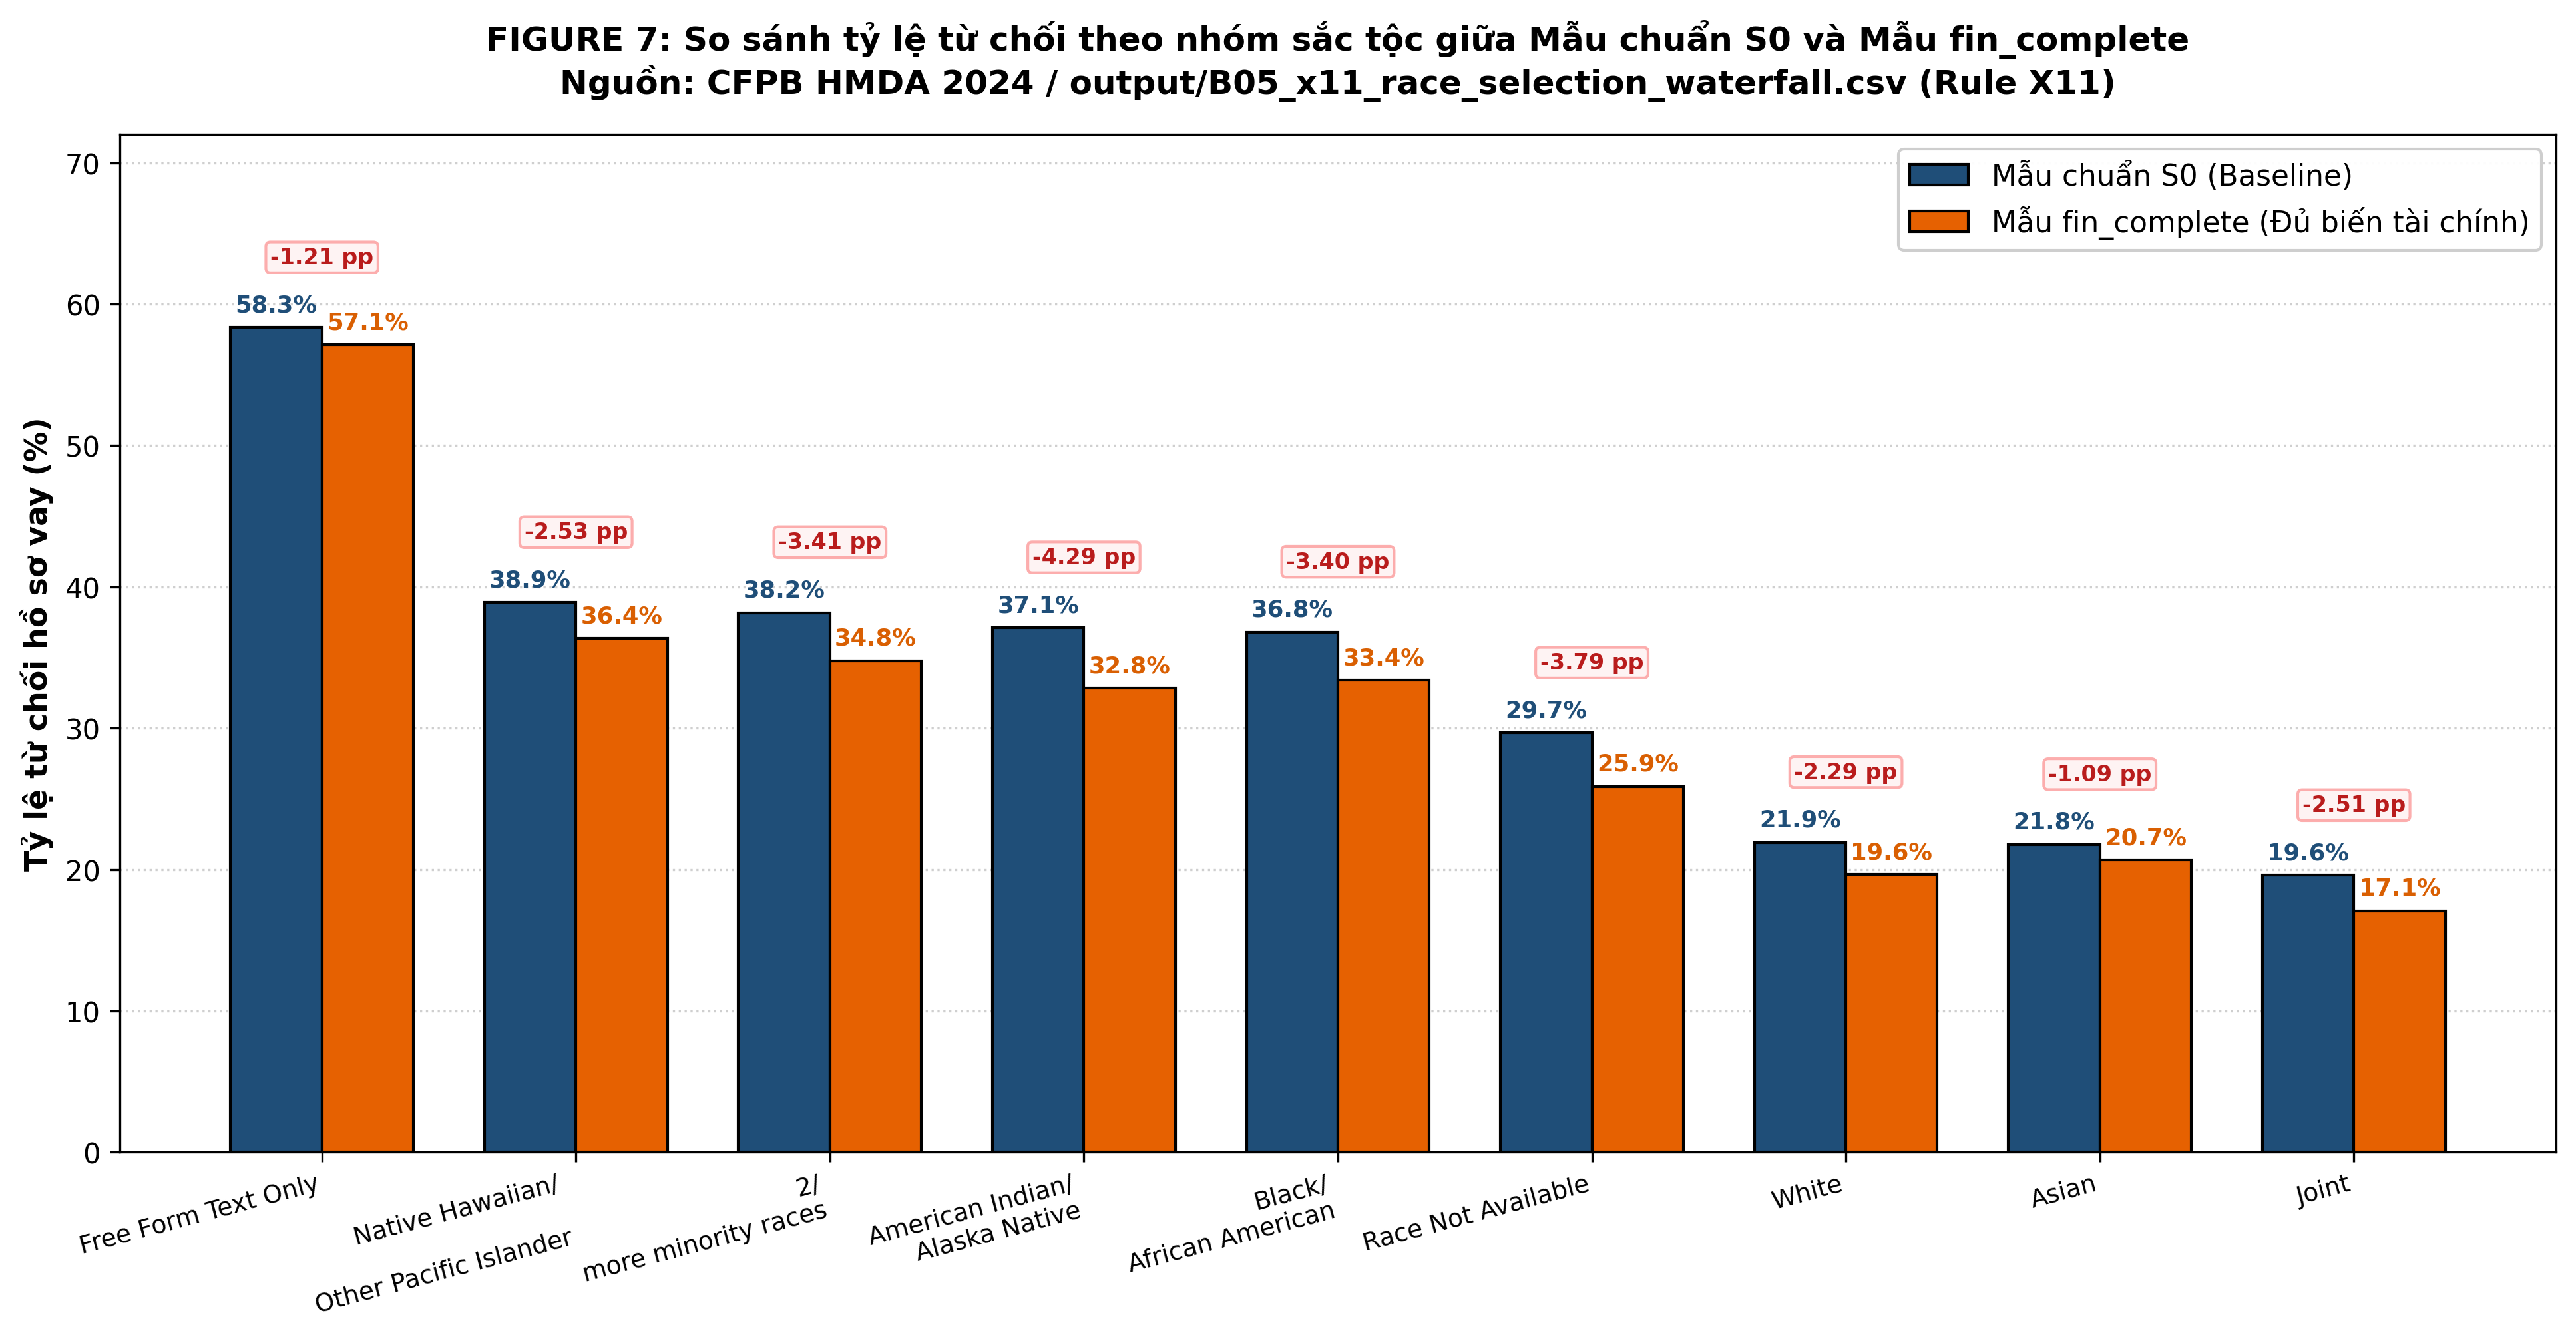

In [76]:
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Đọc dữ liệu và sắp xếp theo tỷ lệ từ chối S0 giảm dần
df_race = pd.read_csv(OUTPUT_DIR / 'B05_x11_race_selection_waterfall.csv')
df_s = df_race.sort_values(by='s0_denial_rate_pct', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 6.8), dpi=300)
x = np.arange(len(df_s))
w = 0.36

# Step 2: Vẽ 2 cột nhóm: Mẫu chuẩn S0 (Xanh navy) vs. fin_complete (Cam đất)
ax.bar(x - w/2, df_s['s0_denial_rate_pct'], w, label='Mẫu chuẩn S0 (Baseline)', color='#1f4e78', edgecolor='black', linewidth=1, zorder=3)
ax.bar(x + w/2, df_s['fin_denial_rate_pct'], w, label='Mẫu fin_complete (Đủ biến tài chính)', color='#e66101', edgecolor='black', linewidth=1, zorder=3)

# Step 3: Gắn nhãn tỷ lệ % và mức dịch chuyển (Shift Badge) trên đỉnh cột
for i in range(len(df_s)):
    v_s0, v_fin = df_s['s0_denial_rate_pct'].iloc[i], df_s['fin_denial_rate_pct'].iloc[i]
    shift = df_s['denial_shift_s0_to_fin_pp'].iloc[i]
    ax.text(x[i] - w/2, v_s0 + 0.8, f'{v_s0:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#1f4e78')
    ax.text(x[i] + w/2, v_fin + 0.8, f'{v_fin:.1f}%', ha='center', va='bottom', fontsize=8.5, fontweight='bold', color='#d95f02')
    ax.text(x[i], max(v_s0, v_fin) + 4.2, f'{shift:+.2f} pp', ha='center', va='bottom', fontsize=8, fontweight='semibold', color='#b91c1c',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='#fef2f2', edgecolor='#fca5a5', alpha=0.9), zorder=4)

ax.set_xticks(x)
ax.set_xticklabels([r.replace(' or ', '/\n').replace('Native Hawaiian/', 'Native Hawaiian/\n') for r in df_s['derived_race']], fontsize=9, rotation=15, ha='right')
ax.set_ylabel('Tỷ lệ từ chối hồ sơ vay (%)', fontsize=11, fontweight='bold')
ax.set_ylim(0, 72); ax.grid(axis='y', linestyle=':', alpha=0.6, zorder=0); ax.set_axisbelow(True)
ax.legend(loc='upper right', frameon=True, fontsize=10.5, framealpha=0.95)
ax.set_title('FIGURE 7: So sánh tỷ lệ từ chối theo nhóm sắc tộc giữa Mẫu chuẩn S0 và Mẫu fin_complete\nNguồn: CFPB HMDA 2024 / output/B05_x11_race_selection_waterfall.csv (Rule X11)', fontsize=12, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'B05_figure_7_race_denial_shift.png', dpi=300)
plt.show()

## Section 7.4b: Step B-2.6 — Corrected Dual S5 Robustness Variations & V-Rule Impact (Decision D-C & Rulebook v2.3)

- **Input:** `B04_raw_with_buckets.parquet` restricted to Analytic Baseline $S0$.
- **Process:**
  - **Correction of S5 Specification per Decision D-C and Rulebook v2.3:**
    Rule V04 (`interest_rate <= 0`) carries **0 denied loans** (100% of denied loans have missing rate). Mistakenly excluding V04 removes 60,717 approved loans and artificially inflates the S5 denial rate by **+0.18 pp** (from `24.18%` in `S5_all` to `24.36%` in `Old S5_all`, as of run 2026-10-31, cell 43).
    Conversely, Rule V02 (`income <= 0`) carries a **60.49% denial rate** (95.51% on negative income, as of run 2026-10-31, cell 43). Removing V02 drops 55,207 denials and artificially compresses the denial rate by **-0.40 pp** (from `24.58%` in `S5_keep_v02` down to `24.18%` in `S5_all`, as of run 2026-10-31, cell 43).
  - Therefore, per Rulebook v2.3 (§7) and Decision D-C, **V04 is NEVER excluded from S5**:
    1. `S5_all`: Exclude V01, V02, V03, V05; **KEEP V04** (8,041,498 apps, denial rate 24.18%, as of run 2026-10-31, cell 43).
    2. `S5_keep_v02`: Exclude V01, V03, V05; **KEEP V02 and V04** (8,132,620 apps, denial rate 24.58%, as of run 2026-10-31, cell 43).
    3. `[Diagnostic Only] Old S5_all`: Included to demonstrate the confounding effect of mistakenly excluding V04 (7,981,245 apps, 24.36%, as of run 2026-10-31, cell 43).
- **Output:** Exported `output/B05_s5_robustness_v_rules.csv`.

In [67]:
# Step 1: Query Corrected Dual S5 Robustness Variations (V04 Kept per Decision D-C)
s5_sql = f"""
WITH s0_data AS (
    SELECT TRIM(action_taken) = '3' AS is_denied,
        try_cast(TRIM(loan_amount) AS DOUBLE) <= 0 AS v01,
        try_cast(TRIM(income) AS DOUBLE) <= 0 AS v02,
        try_cast(TRIM(income) AS DOUBLE) < 0 AS v02_neg,
        try_cast(TRIM(income) AS DOUBLE) = 0 AS v02_zero,
        (try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) <= 0
         OR try_cast(TRIM(combined_loan_to_value_ratio) AS DOUBLE) > 200) AS v03,
        (try_cast(TRIM(interest_rate) AS DOUBLE) <= 0
         OR try_cast(TRIM(interest_rate) AS DOUBLE) > 25) AS v04,
        (try_cast(TRIM(loan_term) AS DOUBLE) < 1
         OR try_cast(TRIM(loan_term) AS DOUBLE) > 480) AS v05
    FROM read_parquet('{INPUT_PARQUET.as_posix()}') WHERE {S0_SQL_PRED}
)
SELECT 'All S0 (Baseline)' AS sample_specification, COUNT(*)::BIGINT AS total_apps,
       COUNT(*) FILTER (WHERE is_denied)::BIGINT AS denied_apps,
       ROUND(AVG(is_denied::DOUBLE) * 100, 2) AS denial_rate_pct FROM s0_data
UNION ALL SELECT 'Flag V01 (loan_amount <= 0)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v01
UNION ALL SELECT 'Flag V02 (income <= 0: All)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v02
UNION ALL SELECT '  -> V02_neg (income < 0)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v02_neg
UNION ALL SELECT '  -> V02_zero (income = 0)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v02_zero
UNION ALL SELECT 'Flag V03 (CLTV <= 0 or > 200)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v03
UNION ALL SELECT 'Flag V04 (interest_rate <= 0: 0 denied)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v04
UNION ALL SELECT 'Flag V05 (loan_term < 1 or > 480 mo)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2) FROM s0_data WHERE v05
UNION ALL SELECT 'Robustness S5_all (Exclude V01,V02,V03,V05; KEEP V04)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2)
FROM s0_data WHERE NOT (COALESCE(v01, FALSE) OR COALESCE(v02, FALSE) OR COALESCE(v03, FALSE) OR COALESCE(v05, FALSE))
UNION ALL SELECT 'Robustness S5_keep_v02 (Exclude V01,V03,V05; KEEP V02 & V04)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2)
FROM s0_data WHERE NOT (COALESCE(v01, FALSE) OR COALESCE(v03, FALSE) OR COALESCE(v05, FALSE))
UNION ALL SELECT '[Diagnostic Only] Old S5_all (mistakenly excluded V04)', COUNT(*)::BIGINT, COUNT(*) FILTER (WHERE is_denied)::BIGINT, ROUND(AVG(is_denied::DOUBLE)*100, 2)
FROM s0_data WHERE NOT (COALESCE(v01, FALSE) OR COALESCE(v02, FALSE) OR COALESCE(v03, FALSE) OR COALESCE(v04, FALSE) OR COALESCE(v05, FALSE))
"""
s5_df = duck_conn.execute(s5_sql).df()
save_and_log(s5_df, 'B05_s5_robustness_v_rules.csv')
display(s5_df)

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_s5_robustness_v_rules.csv | Size: 0.65 KB (665 bytes) | Shape: (11, 4)


,sample_specification,total_apps,denied_apps,denial_rate_pct
0,All S0 (Baseline),8136664,2003276,24.62
1,Flag V01 (loan_amount <= 0),0,0,NaN
2,Flag V02 (income <= 0: All),91261,55207,60.49
3,-> V02_neg (income < 0),6905,6595,95.51
4,-> V02_zero (income = 0),84356,48612,57.63
5,Flag V03 (CLTV <= 0 or > 200),4026,3896,96.77
6,Flag V04 (interest_rate <= 0: 0 denied),60717,0,0.00
7,Flag V05 (loan_term < 1 or > 480 mo),18,13,72.22
8,"Robustness S5_all (Exclude V01,V02,V03,V05; KE...",8041498,1944293,24.18
9,"Robustness S5_keep_v02 (Exclude V01,V03,V05; K...",8132620,1999367,24.58


## Section 8: Step B-2.7 — Dynamic Milestone Summary & Hand-off

- **Input:** Diagnostic DataFrames computed across Sections 2 through 7.
- **Process:**
  - Assemble the master milestone ledger dynamically from computed Python variables without any hard-coded statistics (Convention 4.3).
  - Export `B05_profiling_gap_summary.csv` and close the DuckDB connection cleanly.
- **Output:** Verified summary artifact `output/B05_profiling_gap_summary.csv`.

In [68]:
# Step 1: Extract dynamic summary metrics from preceding DataFrames (zero hard-coded numbers)
tot_padded = int(sentinels_99_df['padded_count'].sum())
tot_unparseable = int(t03_cast_df['unparseable_count'].sum())
dr1_co_28_pct = round(dr_co_df.loc[dr_co_df['other_28_status'].str.startswith('n_exempt_28 == 28'), 'dr1_is_1111'].iloc[0] * 100.0 / dr_co_df.loc[dr_co_df['other_28_status'].str.startswith('n_exempt_28 == 28'), 'total_rows'].iloc[0], 2)
purch_8888_pct = age_df.loc[age_df['action_taken'] == '6', 'share_of_all_app_8888_pct'].iloc[0]
sub_zero_share = rate_lien_df.loc[rate_lien_df['lien_status'] == '2', 'share_of_all_zero_rates_pct'].iloc[0]
sub_zero_rep_pct = rate_lien_df.loc[rate_lien_df['lien_status'] == '2', 'zero_rate_pct_of_reported'].iloc[0]
denied_rep_rates = int(rate_act_df.loc[rate_act_df['action_taken'] == '3', 'rate_valid_pos_count'].iloc[0] + rate_act_df.loc[rate_act_df['action_taken'] == '3', 'rate_le0_v04_count'].iloc[0])
t12_inc_cnt_pop_pos_zeros = int(tract_domain_df.loc[tract_domain_df['column_name'] == 'tract_to_msa_income_percentage', 'zero_pop_pos_cnt'].iloc[0])

# Pre-RQ3 missing tract and V02 / S5 stats extracted dynamically
s0_tract_na_apps, s0_tract_na_denial = int(tract_rq3_df.loc[tract_rq3_df['derived_race'] == 'All S0 (Overall)', 'na_tract_apps'].iloc[0]), tract_rq3_df.loc[tract_rq3_df['derived_race'] == 'All S0 (Overall)', 'na_tract_denial_rate_pct'].iloc[0]
black_tract_na_pct, aian_tract_na_pct = tract_rq3_df.loc[tract_rq3_df['derived_race'] == 'Black or African American', 'na_tract_share_pct'].iloc[0], tract_rq3_df.loc[tract_rq3_df['derived_race'] == 'American Indian or Alaska Native', 'na_tract_share_pct'].iloc[0]
v02_all_denial_pct, v02_neg_denial_pct = s5_df.loc[s5_df['sample_specification'] == 'Flag V02 (income <= 0: All)', 'denial_rate_pct'].iloc[0], s5_df.loc[s5_df['sample_specification'] == '  -> V02_neg (income < 0)', 'denial_rate_pct'].iloc[0]
fha_below_min_pct, conv_below_min_pct = cltv_lt_df.loc[cltv_lt_df['loan_type'] == '2', 'below_min_1pp_pct'].iloc[0], cltv_lt_df.loc[cltv_lt_df['loan_type'] == '1', 'below_min_1pp_pct'].iloc[0]
s5_all_denial_pct, s5_keepv02_denial_pct = s5_df.loc[s5_df['sample_specification'].str.startswith('Robustness S5_all'), 'denial_rate_pct'].iloc[0], s5_df.loc[s5_df['sample_specification'].str.startswith('Robustness S5_keep_v02'), 'denial_rate_pct'].iloc[0]

# Step 2: Assemble dynamic milestone ledger DataFrame
summary_rows = [
    {'Item': '99-Col Whitespace, Sentinels & T03', 'Finding': f'{tot_padded:,} padded cells (T01); {tot_unparseable} unparseable numeric strings across {len(t03_cast_df)} numeric cols (T03)', 'Artifact': 'B05_sentinels_99_columns.csv / B05_t03_numeric_cast_audit.csv'},
    {'Item': 'Rule T06 & X09 (28 Doc Fields)', 'Finding': f'{len(dict_has_1111)} Dict-Verified 1111 cols; X09 n=28: {full_exempt_raw:,} raw ({full_exempt_s0:,} S0), 1<=n<=27: {partial_exempt_raw:,} raw ({partial_exempt_s0:,} S0); dr1=1111 in {dr1_co_28_pct}% of n=28', 'Artifact': 'B05_denial_reason_1111_cooccurrence.csv / B05_x09_exempt_filer_distribution.csv'},
    {'Item': 'Rule T08 & 4-State X05', 'Finding': f'Applicant 8888 is {purch_8888_pct}% in purchased; {tot_discordant_raw:,} discordant rows ({tot_discordant_s0:,} in S0); only {tot_all_na_s0:,} unresolved all-NA in S0', 'Artifact': 'B05_age_sentinels_crosstab.csv / B05_coapplicant_agreement.csv'},
    {'Item': 'Sequential Waterfall & V02', 'Finding': f'Raw ({total_raw_rows:,}) -> F01 ({tot_f01:,}) -> F02 ({tot_f02:,}) -> S0 ({tot_analytic:,}); V02 income<=0 is {v02_all_denial_pct:.1f}% denied ({v02_neg_denial_pct:.1f}% on negative income)', 'Artifact': 'B05_waterfall_f01_f03.csv / B05_v02_income_by_action.csv'},
    {'Item': 'Rule V04 & D-C Audit', 'Finding': f'{sub_zero_share}% of zero-rate loans in lien=2 ({sub_zero_rep_pct}% of reported); action=3 has {denied_rep_rates} reported rates', 'Artifact': 'B05_zero_rate_diagnostic.csv / B05_interest_rate_by_action.csv'},
    {'Item': '4-Col T05, V06 & V07 Guard', 'Finding': f'{len(tract_anomaly_df)} lowercase na standardized; derived_msa_md=99999 is non_msa; V07 guard prevents {v07_div_cnt:,} bidirectional divergence rows', 'Artifact': 'B05_geo_id_audit.csv / B05_census_tract_anomaly.csv'},
    {'Item': 'Per-Field T12 & Pre-RQ3 Tract Audit', 'Finding': f'Tract_to_msa_income_pct has {t12_inc_cnt_pop_pos_zeros:,} zeros on pop>0 tracts; {s0_tract_na_apps:,} S0 rows lack tract with {s0_tract_na_denial:.2f}% denial rate ({black_tract_na_pct:.2f}% Black, {aian_tract_na_pct:.2f}% AIAN)', 'Artifact': 'B05_tract_domain_audit.csv / B05_tract_na_rq3_crosstab.csv'},
    {'Item': 'V09 Profile & Corrected Dual S5', 'Finding': f'First-lien CLTV < min bound: FHA is {fha_below_min_pct}% vs Conv {conv_below_min_pct}%; Dual S5 (V04 kept): S5_all={s5_all_denial_pct}% vs S5_keep_v02={s5_keepv02_denial_pct}%', 'Artifact': 'B05_v09_cltv_by_loantype.csv / B05_s5_robustness_v_rules.csv'}
]
b05_summary_df = pd.DataFrame(summary_rows)
save_and_log(b05_summary_df, 'B05_profiling_gap_summary.csv')
duck_conn.close()
display(b05_summary_df)
print("\\n[SUCCESS] Task B05 (v5 Calibrated) completed. All calibration artifacts exported for Stage B-3 / B-4.")

Saved: d:\H-NEU\004\44 - Big Data\Final project\B05 - 30 Oct\output\B05_profiling_gap_summary.csv | Size: 1.64 KB (1,677 bytes) | Shape: (8, 3)


,Item,Finding,Artifact
0,"99-Col Whitespace, Sentinels & T03",0 padded cells (T01); 0 unparseable numeric st...,B05_sentinels_99_columns.csv / B05_t03_numeric...
1,Rule T06 & X09 (28 Doc Fields),"14 Dict-Verified 1111 cols; X09 n=28: 276,755 ...",B05_denial_reason_1111_cooccurrence.csv / B05_...
2,Rule T08 & 4-State X05,"Applicant 8888 is 80.98% in purchased; 79,088 ...",B05_age_sentinels_crosstab.csv / B05_coapplica...
3,Sequential Waterfall & V02,"Raw (12,259,199) -> F01 (8,661,779) -> F02 (8,...",B05_waterfall_f01_f03.csv / B05_v02_income_by_...
4,Rule V04 & D-C Audit,95.34% of zero-rate loans in lien=2 (5.22% of ...,B05_zero_rate_diagnostic.csv / B05_interest_ra...
5,"4-Col T05, V06 & V07 Guard",1 lowercase na standardized; derived_msa_md=99...,B05_geo_id_audit.csv / B05_census_tract_anomal...
6,Per-Field T12 & Pre-RQ3 Tract Audit,"Tract_to_msa_income_pct has 57,954 zeros on po...",B05_tract_domain_audit.csv / B05_tract_na_rq3_...
7,V09 Profile & Corrected Dual S5,First-lien CLTV < min bound: FHA is 19.75% vs ...,B05_v09_cltv_by_loantype.csv / B05_s5_robustne...


\n[SUCCESS] Task B05 (v5 Calibrated) completed. All calibration artifacts exported for Stage B-3 / B-4.
